In [ ]:
from google.colab import drive; drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
"""
Central configuration for the cross-site generalization study.

Edit the paths below to match where you mounted/copied the UT-EndoMRI
dataset (e.g. inside Google Colab after `drive.mount(...)`).

Actual UT-EndoMRI layout (per the dataset README):

    DATA_ROOT/
        D1_MHS/
            D1-000/
                D1-000_T1.nii.gz
                D1-000_T1FS.nii.gz
                D1-000_T2.nii.gz
                D1-000_T2FS.nii.gz
                D1-000_ut_r1.nii.gz      <- uterus, rater 1
                D1-000_ut_r2.nii.gz      <- uterus, rater 2 (if present)
                D1-000_ov_r1.nii.gz      <- ovary, rater 1
                D1-000_em_r1.nii.gz      <- endometrioma, rater 1
                ...
            D1-001/
                ...
        D2_TCPW/
            D2-006/
                D2-006_T2.nii.gz
                D2-006_ut.nii.gz         <- single rater, no _r suffix
                D2-006_ov.nii.gz
                ...

Not every patient has every MRI sequence or every structure label
(sequences may be missing due to acquisition; some structures may not
have been contoured for a given patient).
"""

import os

# ---- Paths -------------------------------------------------------------
DATA_ROOT = "/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI"

SITE_A_NAME = "D1_MHS"    # training / in-distribution site
SITE_B_NAME = "D2_TCPW"   # external / out-of-distribution site

SITE_A_DIR = os.path.join(DATA_ROOT, SITE_A_NAME)
SITE_B_DIR = os.path.join(DATA_ROOT, SITE_B_NAME)

OUTPUT_DIR = "/content/outputs"   # checkpoints, csvs, plots all go here
CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "unet_site_a.pt")

# ---- MRI sequence selection ----------------------------------------------
# T2 ONLY, for both sites. D1 has no T2FS and D2 has T2 as well, so using
# plain T2 everywhere keeps image contrast matched across sites. There is
# deliberately NO fallback sequence: patients without a T2 image are
# excluded, so no site can silently get a different contrast.
MRI_SEQUENCE_PRIORITY = ["T2"]

# ---- Structures / labels ---------------------------------------------------
# Maps the dataset's structure abbreviation -> the integer class id to use
# in the combined multi-class mask. 0 = background is implicit; do not use
# 0 here. Order matters when structures overlap in space: later entries
# are drawn ON TOP of earlier ones (see data.load_combined_mask).
STRUCTURES_OF_INTEREST = {
    "ut": 1,   # uterus
    "ov": 2,   # ovary
    "em": 3,   # endometrioma
}
LABEL_MAP = {0: "background"}
for abbrev, class_id in STRUCTURES_OF_INTEREST.items():
    LABEL_MAP[class_id] = {"ut": "uterus", "ov": "ovaries", "em": "endometrioma",
                            "cy": "cyst", "cds": "cul_de_sac"}.get(abbrev, abbrev)
NUM_CLASSES = len(LABEL_MAP)

# When a structure has multiple raters (D1_MHS only), prefer this rater ID
# if available, otherwise fall back to whichever rater's file exists.
PREFERRED_RATER = "r1"

# If a patient is missing a label file for one of STRUCTURES_OF_INTEREST
# entirely, we still include them (that structure is treated as "not
# present" i.e. all background for that structure) rather than dropping
# the whole case.
REQUIRE_ALL_STRUCTURES = False

# ---- Data / preprocessing ------------------------------------------------
IMAGE_SIZE = 256
SLICE_AXIS = 2              # axial slicing; 0/1/2 = sagittal/coronal/axial

MIN_FOREGROUND_PIXELS = 10  # skip slices with fewer than this many
                             # foreground pixels (mostly-empty slices)

# train/val split done WITHIN site A only (site B is never used for
# training or model selection it's held out entirely for the
# generalization test)
VAL_FRACTION = 0.2
RANDOM_SEED = 42

# ---- Training --------------------------------------------------------------
BATCH_SIZE = 8
NUM_EPOCHS = 40
LEARNING_RATE = 1e-3
BASE_CHANNELS = 32          # width of the first U-Net stage
DEVICE = "cuda"              # falls back to "cpu" automatically if no GPU
NUM_WORKERS = 2

In [ ]:
import os
import glob
import numpy as np
import nibabel as nib
from nibabel.processing import resample_from_to
import torch
from torch.utils.data import Dataset
from skimage.transform import resize


def find_image_path(patient_dir, patient_id):
    """Pick the first available MRI sequence for this patient, in
    MRI_SEQUENCE_PRIORITY order. Returns (path, sequence_name) or
    (None, None) if no listed sequence is present. """
    for seq in MRI_SEQUENCE_PRIORITY:
        candidate = os.path.join(patient_dir, f"{patient_id}_{seq}.nii.gz")
        if os.path.exists(candidate):
            return candidate, seq

    existing = sorted(os.path.basename(p) for p in
                       glob.glob(os.path.join(patient_dir, "*.nii.gz")))
    print(f"[warn] {patient_id}: none of "
          f"{ [f'{patient_id}_{s}.nii.gz' for s in MRI_SEQUENCE_PRIORITY]} "
          f"found. Files actually present: {existing}")
    return None, None


def find_structure_label_path(patient_dir, patient_id, structure):
    """
    Find the label file for one structure abbreviation (e.g. 'ut').

    Handles both naming conventions:
      - D1_MHS (multi-rater): {patient_id}_{structure}_r{rater}.nii.gz
      - D2_TCPW (single rater): {patient_id}_{structure}.nii.gz

    Prefers PREFERRED_RATER if multiple raters exist, otherwise
    falls back to whichever rater's file is found first (sorted).
    Returns None if no matching file exists at all.
    """
    # single-rater / no-rater-suffix convention (D2_TCPW)
    plain_path = os.path.join(patient_dir, f"{patient_id}_{structure}.nii.gz")
    if os.path.exists(plain_path):
        return plain_path

    # multi-rater convention (D1_MHS)
    rater_pattern = os.path.join(patient_dir, f"{patient_id}_{structure}_r*.nii.gz")
    rater_files = sorted(glob.glob(rater_pattern))
    if not rater_files:
        return None

    preferred = os.path.join(patient_dir,
                              f"{patient_id}_{structure}_{PREFERRED_RATER}.nii.gz")
    if preferred in rater_files:
        return preferred
    return rater_files[0]  # fall back to first available rater


def discover_cases(site_dir):
    """
    Walk a site directory and build a list of case records:
        {
            "case_id": "D1-000",
            "site_dir": <path>,
            "image_path": <path>,
            "sequence": "T2FS",
            "label_paths": {"ut": <path or None>, "ov": <path or None>},
        }
    Patients missing an MRI sequence entirely are skipped.
     Patients missing some structure labels are kept unless
    REQUIRE_ALL_STRUCTURES is True
    """
    patient_dirs = sorted(
        d for d in glob.glob(os.path.join(site_dir, "*")) if os.path.isdir(d)
    )
    if not patient_dirs:
        raise FileNotFoundError(
            f"No patient subfolders found under {site_dir}. "
            f"Check DATA_ROOT / site folder names."
        )

    cases = []
    for patient_dir in patient_dirs:
        patient_id = os.path.basename(patient_dir.rstrip("/"))

        image_path, sequence = find_image_path(patient_dir, patient_id)
        if image_path is None:
            print(f"[warn] {patient_id}: skipping patient (no usable sequence)")
            continue

        label_paths = {}
        for structure in STRUCTURES_OF_INTEREST:
            label_paths[structure] = find_structure_label_path(
                patient_dir, patient_id, structure
            )

        missing = [s for s, p in label_paths.items() if p is None]
        if missing:
            msg = f"[warn] {patient_id}: missing label(s) for {missing}"
            if REQUIRE_ALL_STRUCTURES:
                print(msg + " -> skipping patient (REQUIRE_ALL_STRUCTURES=True)")
                continue
            else:
                print(msg + " -> treating as background for that structure")

        if all(p is None for p in label_paths.values()):
            print(f"[warn] {patient_id}: no structure labels found at all, "
                  f"skipping patient")
            continue

        cases.append({
            "case_id": patient_id,
            "site_dir": site_dir,
            "image_path": image_path,
            "sequence": sequence,
            "label_paths": label_paths,
        })

    print(f"[data] {os.path.basename(site_dir)}: {len(cases)} usable "
          f"patients out of {len(patient_dirs)} folders found")
    return cases


def load_combined_mask(image_nii, label_paths):
    """
    Build a single multi-class mask array, in the IMAGE's coordinate
    grid, from the per-structure label files for one case.

    Label files are frequently saved on a different voxel grid than the
    image itself even though they cover the same
    physical anatomy. Comparing raw array shapes and skipping on
    mismatch throws away good data. Instead, every label is resampled
    onto the image's grid using the NIfTI affine transforms

    Missing structures (None path) contribute nothing (stay
    background). Classes are drawn in STRUCTURES_OF_INTEREST
    order, so later structures are painted ON TOP of earlier ones if
    they ever overlap.
    """
    image_shape = image_nii.shape
    mask = np.zeros(image_shape, dtype=np.int64)

    for structure, class_id in STRUCTURES_OF_INTEREST.items():
        path = label_paths.get(structure)
        if path is None:
            continue

        label_nii = nib.load(path)

        same_grid = (label_nii.shape == image_shape and
                     np.allclose(label_nii.affine, image_nii.affine, atol=1e-3))

        if same_grid:
            vol = label_nii.get_fdata()
        else:
            try:
                # order=0 = nearest-neighbor, required for label data
                # (linear/cubic interpolation would invent fractional
                # class values between e.g. 0 and 1)
                resampled_nii = resample_from_to(label_nii, image_nii, order=0)
                vol = resampled_nii.get_fdata()
            except Exception as e:
                print(f"[warn] could not resample {path} onto the image "
                      f"grid ({label_nii.shape} -> {image_shape}): {e}. "
                      f"Skipping this structure for this case.")
                continue

        mask[vol > 0.5] = class_id

    return mask


def normalize_intensity(slice_2d):
    """Percentile-clip then min-max normalize a single MRI slice to [0, 1]."""
    p1, p99 = np.percentile(slice_2d, (1, 99))
    slice_2d = np.clip(slice_2d, p1, p99)
    denom = (p99 - p1) if (p99 - p1) > 1e-6 else 1.0
    return (slice_2d - p1) / denom


def extract_slices(case, site_name):
    """Load one case's volume + combined mask, return per-slice records.

    Both the image and (via resample_from_to) the mask are reoriented to
    a canonical axis ordering (RAS+) before slicing.
    """
    image_nii = nib.load(case["image_path"])
    image_nii = nib.as_closest_canonical(image_nii)
    img_vol = image_nii.get_fdata().astype(np.float32)
    mask_vol = load_combined_mask(image_nii, case["label_paths"])

    n_slices = img_vol.shape[SLICE_AXIS]
    records = []
    for i in range(n_slices):
        img_slice = np.take(img_vol, i, axis=SLICE_AXIS)
        mask_slice = np.take(mask_vol, i, axis=SLICE_AXIS)

        if np.count_nonzero(mask_slice) < MIN_FOREGROUND_PIXELS:
            continue  # skip near-empty slices

        records.append({
            "case_id": case["case_id"],
            "site": site_name,
            "slice_idx": i,
            "image": img_slice,
            "mask": mask_slice,
        })
    return records


class EndoMRISliceDataset(Dataset):
    """
    2D slice dataset built from a list of case records
    """

    def __init__(self, cases, site_name, augment=False):
        self.site_name = site_name
        self.augment = augment
        self.records = []
        for case in cases:
            self.records.extend(extract_slices(case, site_name))
        print(f"[data] {site_name}: {len(cases)} cases -> "
              f"{len(self.records)} usable slices")

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        rec = self.records[idx]
        img = normalize_intensity(rec["image"])
        mask = rec["mask"]

        img = resize(img, (IMAGE_SIZE, IMAGE_SIZE),
                     order=1, preserve_range=True, anti_aliasing=True)
        mask = resize(mask, (IMAGE_SIZE, IMAGE_SIZE),
                      order=0, preserve_range=True, anti_aliasing=False)

        if self.augment and np.random.rand() < 0.5:
            img = np.fliplr(img).copy()
            mask = np.fliplr(mask).copy()

        image_t = torch.from_numpy(img).float().unsqueeze(0)
        mask_t = torch.from_numpy(mask).long()

        meta = {
            "case_id": rec["case_id"],
            "site": rec["site"],
            "slice_idx": rec["slice_idx"],
        }
        return image_t, mask_t, meta


def split_cases_train_val(cases, val_fraction, seed):
    """Split at the CASE level (not slice level) to avoid leaking slices
    from the same patient across train/val."""
    rng = np.random.RandomState(seed)
    idx = np.arange(len(cases))
    rng.shuffle(idx)
    n_val = max(1, int(len(idx) * val_fraction))
    val_idx = set(idx[:n_val])
    train_cases = [c for i, c in enumerate(cases) if i not in val_idx]
    val_cases = [c for i, c in enumerate(cases) if i in val_idx]
    return train_cases, val_cases


In [ ]:
"""
2D U-Net.
"""

import torch
import torch.nn as nn


def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, 3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, 3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class SmallUNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=3, base_channels=32):
        super().__init__()
        c = base_channels

        self.enc1 = conv_block(in_channels, c)
        self.enc2 = conv_block(c, c * 2)
        self.enc3 = conv_block(c * 2, c * 4)
        self.enc4 = conv_block(c * 4, c * 8)

        self.pool = nn.MaxPool2d(2)

        self.bottleneck = conv_block(c * 8, c * 16)

        self.up4 = nn.ConvTranspose2d(c * 16, c * 8, 2, stride=2)
        self.dec4 = conv_block(c * 16, c * 8)
        self.up3 = nn.ConvTranspose2d(c * 8, c * 4, 2, stride=2)
        self.dec3 = conv_block(c * 8, c * 4)
        self.up2 = nn.ConvTranspose2d(c * 4, c * 2, 2, stride=2)
        self.dec2 = conv_block(c * 4, c * 2)
        self.up1 = nn.ConvTranspose2d(c * 2, c, 2, stride=2)
        self.dec1 = conv_block(c * 2, c)

        self.out_conv = nn.Conv2d(c, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.up4(b)
        d4 = self.dec4(torch.cat([d4, e4], dim=1))
        d3 = self.up3(d4)
        d3 = self.dec3(torch.cat([d3, e3], dim=1))
        d2 = self.up2(d3)
        d2 = self.dec2(torch.cat([d2, e2], dim=1))
        d1 = self.up1(d2)
        d1 = self.dec1(torch.cat([d1, e1], dim=1))

        return self.out_conv(d1)  # logits, shape [B, num_classes, H, W]

In [ ]:
"""
Loss function and evaluation metrics.

Dice score is computed per class.
"""

import torch
import torch.nn as nn
import torch.nn.functional as F


class DiceCELoss(nn.Module):
    """Combined Dice + cross-entropy loss for multi-class segmentation."""

    def __init__(self, num_classes, ce_weight=0.5):
        super().__init__()
        self.num_classes = num_classes
        self.ce_weight = ce_weight
        self.ce = nn.CrossEntropyLoss()

    def forward(self, logits, target):
        ce_loss = self.ce(logits, target)

        probs = F.softmax(logits, dim=1)
        target_onehot = F.one_hot(target, self.num_classes)
        target_onehot = target_onehot.permute(0, 3, 1, 2).float()

        dims = (0, 2, 3)
        intersection = torch.sum(probs * target_onehot, dims)
        cardinality = torch.sum(probs + target_onehot, dims)
        dice_per_class = (2.0 * intersection + 1e-6) / (cardinality + 1e-6)
        dice_loss = 1.0 - dice_per_class.mean()

        return self.ce_weight * ce_loss + (1 - self.ce_weight) * dice_loss


@torch.no_grad()
def dice_per_class(pred_labels, target_labels, num_classes):
    """
    Compute Dice score for each class on a single 2D prediction/target pair.
    Returns a list of length num_classes
    """
    scores = []
    for c in range(num_classes):
        pred_c = (pred_labels == c)
        target_c = (target_labels == c)
        intersection = (pred_c & target_c).sum().item()
        denom = pred_c.sum().item() + target_c.sum().item()
        if denom == 0:
            scores.append(float("nan"))  # class not present in this slice
        else:
            scores.append(2.0 * intersection / denom)
    return scores

## Experiment design: A-only, B-only and pooled (T2 images only)
Each site is split at the **case level** into train/val/test. Three models are trained and all are tested on the same A_test and B_test cases: `A_only` (A in-site, A->B cross-site), `B_only` (B in-site, B->A cross-site) and `pooled` (A_train + B_train). Leak checks run automatically before every training run.

In [ ]:
"""
Experiment-design config (extends the main config cell; run AFTER it).

Three models, all tested on the SAME held-out A_test and B_test cases:

  A_only : train on A_train,          validate on A_val          (A in-site, A->B cross-site)
  B_only : train on B_train,          validate on B_val          (B in-site, B->A cross-site)
  pooled : train on A_train+B_train,  validate on A_val+B_val

Only T2 images are used for both sites (set in the main config cell:
MRI_SEQUENCE_PRIORITY = ["T2"]), so image contrast is matched across sites.
"""
SPLIT_VAL_FRACTION = 0.15    # per site, at CASE level
SPLIT_TEST_FRACTION = 0.20   # per site, at CASE level
SEEDS = [42]                 # add more (e.g. [42, 43, 44, 45, 46]) to
                             # average over several random splits
EXPERIMENTS = ["A_only", "B_only", "pooled"]
FAILURE_ANALYSIS_EXPERIMENT = "A_only"   # which model the failure-analysis cell inspects


In [ ]:
import hashlib
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
from torch.utils.data import ConcatDataset


# ------------------------------------------------------------------ splits
def tag_site(cases, site_name):
    """Attach the site to every case record"""
    for c in cases:
        c["site"] = site_name
    return cases


def split_cases_three_way(cases, val_fraction, test_fraction, seed):
    """Case-level train/val/test split"""
    rng = np.random.RandomState(seed)
    idx = np.arange(len(cases))
    rng.shuffle(idx)
    n = len(idx)
    n_test = max(1, int(round(n * test_fraction)))
    n_val = max(1, int(round(n * val_fraction)))
    if n - n_test - n_val < 1:
        raise ValueError(f"Only {n} cases: not enough for train/val/test.")
    pick = lambda ids: [cases[i] for i in sorted(ids)]
    return (pick(idx[n_test + n_val:]),          # train
            pick(idx[n_test:n_test + n_val]),    # val
            pick(idx[:n_test]))                  # test


def build_splits(cases_a, cases_b, seed):
    """Split each site separately with the same seed."""
    return {
        "A": split_cases_three_way(cases_a, SPLIT_VAL_FRACTION,
                                   SPLIT_TEST_FRACTION, seed),
        "B": split_cases_three_way(cases_b, SPLIT_VAL_FRACTION,
                                   SPLIT_TEST_FRACTION, seed),
    }


def experiment_cases(name, sp):
    A_tr, A_va, A_te = sp["A"]
    B_tr, B_va, B_te = sp["B"]
    tests = {"A_test": A_te, "B_test": B_te}
    if name == "A_only":
        return dict(train=A_tr, val=A_va, tests=tests, allowed_train_sites={"A"})
    if name == "B_only":
        return dict(train=B_tr, val=B_va, tests=tests, allowed_train_sites={"B"})
    if name == "pooled":
        return dict(train=A_tr + B_tr, val=A_va + B_va, tests=tests,
                    allowed_train_sites={"A", "B"})
    raise ValueError(name)


def splits_to_frame(sp, seed):
    rows = []
    for site_key, (tr, va, te) in sp.items():
        for split, lst in [("train", tr), ("val", va), ("test", te)]:
            rows += [{"seed": seed, "site": site_key, "split": split,
                      "case_id": c["case_id"]} for c in lst]
    return pd.DataFrame(rows)


# ------------------------------------------------------------ leak checks
_HASH_CACHE = {}

def volume_hash(path):
    """Hash of the voxel DATA, so the same scan saved
    under a different filename / compression / header is still caught."""
    if path not in _HASH_CACHE:
        arr = np.ascontiguousarray(np.asarray(nib.load(path).dataobj))
        h = hashlib.md5(str(arr.shape).encode() + arr.tobytes()).hexdigest()
        _HASH_CACHE[path] = h
    return _HASH_CACHE[path]


def check_no_leaks(exp_name, spec):
    """Raise AssertionError if anything leaks between train / val / test."""
    sets = {"train": spec["train"], "val": spec["val"], **spec["tests"]}

    # 1+2: case-id / path uniqueness and disjointness
    for k, v in sets.items():
        ids = [c["case_id"] for c in v]
        assert len(ids) == len(set(ids)), f"[{exp_name}] duplicate case_id inside {k}"
    for (k1, v1), (k2, v2) in itertools.combinations(sets.items(), 2):
        ov = {c["case_id"] for c in v1} & {c["case_id"] for c in v2}
        assert not ov, f"[{exp_name}] LEAK: case_ids in both {k1} and {k2}: {sorted(ov)}"
        ov = {c["image_path"] for c in v1} & {c["image_path"] for c in v2}
        assert not ov, f"[{exp_name}] LEAK: image files in both {k1} and {k2}: {sorted(ov)}"

    # 3: identical image content under different case IDs
    seen = {}
    for k, v in sets.items():
        for c in v:
            seen.setdefault(volume_hash(c["image_path"]), []).append((k, c["case_id"]))
    for h, owners in seen.items():
        if len({o[0] for o in owners}) > 1:
            raise AssertionError(f"[{exp_name}] LEAK: identical image volume in "
                                 f"different splits: {owners}")
        if len(owners) > 1:
            print(f"[warn] [{exp_name}] identical image volume inside one split: {owners}")

    # 4: site composition
    train_sites = {c["site"] for c in spec["train"] + spec["val"]}
    expected = {SITE_A_NAME if s == "A" else SITE_B_NAME
                for s in spec["allowed_train_sites"]}
    assert train_sites == expected, (
        f"[{exp_name}] train/val sites are {train_sites}, expected {expected}")
    for name, v in spec["tests"].items():
        want = SITE_A_NAME if name.startswith("A") else SITE_B_NAME
        assert {c["site"] for c in v} == {want}, f"[{exp_name}] {name} has wrong site"

    print(f"[leak-check] {exp_name}: OK  "
          f"(train={len(spec['train'])}, val={len(spec['val'])}, "
          + ", ".join(f"{k}={len(v)}" for k, v in spec["tests"].items()) + " cases)")


def dataset_case_ids(ds):
    parts = ds.datasets if isinstance(ds, ConcatDataset) else [ds]
    return {r["case_id"] for p in parts for r in p.records}


def check_slice_level(exp_name, train_ds, val_ds, test_dss):
    """Verify the actual SLICE datasets only contain their own cases."""
    groups = {"train": dataset_case_ids(train_ds), "val": dataset_case_ids(val_ds),
              **{k: dataset_case_ids(d) for k, d in test_dss.items()}}
    for (k1, s1), (k2, s2) in itertools.combinations(groups.items(), 2):
        assert not (s1 & s2), f"[{exp_name}] SLICE LEAK between {k1} and {k2}: {sorted(s1 & s2)}"
    print(f"[leak-check] {exp_name}: slice-level datasets disjoint")


In [ ]:
import os
import random
import numpy as np
import pandas as pd
import torch
from collections import defaultdict
from torch.utils.data import DataLoader, ConcatDataset
from scipy.stats import wilcoxon


def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def get_device():
    if DEVICE == "cuda" and torch.cuda.is_available():
        return torch.device("cuda")
    print("[device] CUDA not available, falling back to CPU")
    return torch.device("cpu")


def make_dataset(cases, augment):
    """One EndoMRISliceDataset per site, concatenated if more than one."""
    parts = []
    for site in sorted({c["site"] for c in cases}):
        parts.append(EndoMRISliceDataset([c for c in cases if c["site"] == site],
                                         site, augment=augment))
    return parts[0] if len(parts) == 1 else ConcatDataset(parts)


@torch.no_grad()
def run_validation(model, loader, device):
    model.eval()
    all_dice = []
    for images, masks, _ in loader:
        images, masks = images.to(device), masks.to(device)
        preds = torch.argmax(model(images), dim=1)
        for p, m in zip(preds, masks):
            all_dice.append(dice_per_class(p, m, NUM_CLASSES))
    return np.nanmean(np.array(all_dice), axis=0)


def train_model(train_ds, val_ds, ckpt_path, seed):
    """Train + model selection."""
    set_seed(seed)
    device = get_device()
    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                              num_workers=NUM_WORKERS)
    val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False,
                            num_workers=NUM_WORKERS)

    model = SmallUNet(1, NUM_CLASSES, BASE_CHANNELS).to(device)
    criterion = DiceCELoss(NUM_CLASSES)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=4)

    best, history = -1.0, []
    for epoch in range(1, NUM_EPOCHS + 1):
        model.train()
        running = 0.0
        for images, masks, _ in train_loader:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), masks)
            loss.backward()
            optimizer.step()
            running += loss.item() * images.size(0)
        train_loss = running / len(train_ds)

        val_pc = run_validation(model, val_loader, device)
        val_fg = float(np.nanmean(val_pc[1:]))
        scheduler.step(val_fg)
        history.append({"epoch": epoch, "train_loss": train_loss, "val_dice_fg": val_fg})
        print(f"  [epoch {epoch:03d}] train_loss={train_loss:.4f} val_fg_dice={val_fg:.3f}")

        if val_fg > best:
            best = val_fg
            torch.save({"model_state": model.state_dict(), "epoch": epoch,
                        "val_dice_fg": val_fg}, ckpt_path)
    print(f"  best val fg dice = {best:.3f} -> {ckpt_path}")
    return best, pd.DataFrame(history)


def load_model(ckpt_path, device):
    model = SmallUNet(1, NUM_CLASSES, BASE_CHANNELS).to(device)
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    return model


@torch.no_grad()
def evaluate_dataset(model, dataset, device, site_label):
    """Per-case Dice (mean over that case's slices), per class."""
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=NUM_WORKERS)
    per_case = defaultdict(list)
    idx = 0
    for images, masks, _ in loader:
        images, masks = images.to(device), masks.to(device)
        preds = torch.argmax(model(images), dim=1)
        for i in range(images.size(0)):
            cid = dataset.records[idx]["case_id"]
            per_case[cid].append(dice_per_class(preds[i], masks[i], NUM_CLASSES))
            idx += 1
    rows = []
    for cid, lst in per_case.items():
        arr = np.array(lst)
        mean_pc = np.nanmean(arr, axis=0)
        row = {"case_id": cid, "site": site_label, "n_slices_evaluated": arr.shape[0]}
        for c in range(NUM_CLASSES):
            row[f"dice_{LABEL_MAP[c]}"] = mean_pc[c]
        row["dice_foreground_mean"] = np.nanmean(mean_pc[1:])
        rows.append(row)
    return pd.DataFrame(rows)


def _paired(df, exp_a, exp_b, eval_set):
    """Per-case difference (exp_a - exp_b) on identical test cases."""
    cols = ["seed", "case_id", "dice_foreground_mean"]
    a = df[(df.experiment == exp_a) & (df.eval_set == eval_set)][cols]
    b = df[(df.experiment == exp_b) & (df.eval_set == eval_set)][cols]
    m = a.merge(b, on=["seed", "case_id"], suffixes=("_a", "_b")).dropna()
    return (m["dice_foreground_mean_a"] - m["dice_foreground_mean_b"]).values


def _boot_ci(x, n_boot=5000, seed=0):
    rng = np.random.RandomState(seed)
    means = [rng.choice(x, len(x), replace=True).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])


def _boot_ci_unpaired(x, y, n_boot=5000, seed=0):
    rng = np.random.RandomState(seed)
    d = [rng.choice(x, len(x)).mean() - rng.choice(y, len(y)).mean() for _ in range(n_boot)]
    return np.percentile(d, [2.5, 97.5])


def _report_paired(label, d):
    if len(d) < 3:
        print(f"  {label}: only {len(d)} paired cases - skipped"); return
    lo, hi = _boot_ci(d)
    p = wilcoxon(d).pvalue if (d != 0).any() and len(d) >= 5 else float("nan")
    print(f"  {label}: mean diff {d.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  "
          f"Wilcoxon p={p:.3f}  (n={len(d)})")


def summarize(df):
    fg = "dice_foreground_mean"
    dice_cols = [c for c in df.columns if c.startswith("dice_") and c != "dice_background"]

    print("\n=== Train set (rows) x test set (columns): mean foreground Dice per case ===")
    print(df.pivot_table(index="experiment", columns="eval_set", values=fg,
                         aggfunc="mean").reindex(EXPERIMENTS).round(3))
    print("\n=== Same, std / number of test cases ===")
    print(df.groupby(["experiment", "eval_set"])[fg].agg(["std", "count"]).round(3))
    print("\n=== Per-class Dice ===")
    print(df.groupby(["experiment", "eval_set"])[dice_cols].mean().round(3))

    print("\n=== RQ2: cross-site generalisation (in-site reference vs other site) ===")
    for exp, in_set, cross_set, label in [("A_only", "A_test", "B_test", "A -> B"),
                                          ("B_only", "B_test", "A_test", "B -> A")]:
        if exp not in set(df.experiment):
            continue
        x = df[(df.experiment == exp) & (df.eval_set == in_set)][fg].dropna().values
        y = df[(df.experiment == exp) & (df.eval_set == cross_set)][fg].dropna().values
        gap = x.mean() - y.mean()
        lo, hi = _boot_ci_unpaired(x, y)
        rel = 100 * gap / x.mean() if x.mean() > 0 else float("nan")
        print(f"  {label}: in-site {x.mean():.3f}  cross-site {y.mean():.3f}  "
              f"gap {gap:+.3f} ({rel:.0f}% relative)  95% CI [{lo:+.3f}, {hi:+.3f}]")
    print("  (gap compares different patients, so it mixes domain shift with case difficulty)")

    print("\n=== RQ1: pooling vs training on a single site (paired, identical test cases) ===")
    print(" pooled minus the in-site model:")
    _report_paired("A_test: pooled - A_only", _paired(df, "pooled", "A_only", "A_test"))
    _report_paired("B_test: pooled - B_only", _paired(df, "pooled", "B_only", "B_test"))
    print(" pooled minus the cross-site model (benefit of adding the target site):")
    _report_paired("B_test: pooled - A_only", _paired(df, "pooled", "A_only", "B_test"))
    _report_paired("A_test: pooled - B_only", _paired(df, "pooled", "B_only", "A_test"))


def run_all():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    device = get_device()
    cases_a = tag_site(discover_cases(SITE_A_DIR), SITE_A_NAME)
    cases_b = tag_site(discover_cases(SITE_B_DIR), SITE_B_NAME)
    for nm, cs in [(SITE_A_NAME, cases_a), (SITE_B_NAME, cases_b)]:
        seqs = {c["sequence"] for c in cs}
        assert seqs == {"T2"}, f"{nm}: expected only T2 images, got {seqs}"
        print(f"[data] {nm}: {len(cs)} patients with T2 + labels will be used")

    all_rows, split_rows, test_ds_cache = [], [], {}
    for seed in SEEDS:
        sp = build_splits(cases_a, cases_b, seed)
        split_rows.append(splits_to_frame(sp, seed))

        for exp in EXPERIMENTS:
            print(f"\n{'=' * 70}\n seed={seed}  experiment={exp}\n{'=' * 70}")
            spec = experiment_cases(exp, sp)
            check_no_leaks(exp, spec)                       # case/file/volume level

            train_ds = make_dataset(spec["train"], augment=True)
            val_ds = make_dataset(spec["val"], augment=False)
            test_dss = {}
            for name, tcases in spec["tests"].items():      # cache: shared by both exps
                key = (seed, name)
                if key not in test_ds_cache:
                    site = SITE_A_NAME if name.startswith("A") else SITE_B_NAME
                    test_ds_cache[key] = EndoMRISliceDataset(tcases, site, augment=False)
                test_dss[name] = test_ds_cache[key]
            check_slice_level(exp, train_ds, val_ds, test_dss)  # slice level

            ckpt = os.path.join(OUTPUT_DIR, f"unet_{exp}_seed{seed}.pt")
            _, hist = train_model(train_ds, val_ds, ckpt, seed)
            hist.to_csv(os.path.join(OUTPUT_DIR, f"history_{exp}_seed{seed}.csv"), index=False)

            model = load_model(ckpt, device)                # test only AFTER training
            for name, ds in test_dss.items():
                df = evaluate_dataset(model, ds, device, ds.site_name)
                df["experiment"], df["seed"], df["eval_set"] = exp, seed, name
                all_rows.append(df)

    df_all = pd.concat(all_rows, ignore_index=True)
    df_all.to_csv(os.path.join(OUTPUT_DIR, "per_case_metrics_all.csv"), index=False)
    pd.concat(split_rows).to_csv(os.path.join(OUTPUT_DIR, "splits.csv"), index=False)
    summarize(df_all)
    return df_all


df_results = run_all()


[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skipping patient (no usable sequence)
[warn] D1-019: none of ['D1-019_T2.nii.gz'] found. Files actually present: ['D1-019_T1FS.nii.gz',

/tmp/ipykernel_2592/2487679771.py:112: RuntimeWarning: Mean of empty slice
  mean_pc = np.nanmean(arr, axis=0)



 seed=42  experiment=pooled
[leak-check] pooled: OK  (train=58, val=14, A_test=9, B_test=9 cases)
[data] D1_MHS: 29 cases -> 499 usable slices
[data] D2_TCPW: 29 cases -> 277 usable slices
[data] D1_MHS: 7 cases -> 87 usable slices
[data] D2_TCPW: 7 cases -> 66 usable slices
[leak-check] pooled: slice-level datasets disjoint
  [epoch 001] train_loss=0.6641 val_fg_dice=0.000
  [epoch 002] train_loss=0.4281 val_fg_dice=0.133
  [epoch 003] train_loss=0.3767 val_fg_dice=0.122
  [epoch 004] train_loss=0.3561 val_fg_dice=0.128
  [epoch 005] train_loss=0.3464 val_fg_dice=0.109
  [epoch 006] train_loss=0.3366 val_fg_dice=0.117
  [epoch 007] train_loss=0.3310 val_fg_dice=0.106
  [epoch 008] train_loss=0.3178 val_fg_dice=0.125
  [epoch 009] train_loss=0.3122 val_fg_dice=0.153
  [epoch 010] train_loss=0.3042 val_fg_dice=0.123
  [epoch 011] train_loss=0.2986 val_fg_dice=0.147
  [epoch 012] train_loss=0.2920 val_fg_dice=0.155
  [epoch 013] train_loss=0.2899 val_fg_dice=0.141
  [epoch 014] train_lo

/tmp/ipykernel_2592/2487679771.py:112: RuntimeWarning: Mean of empty slice
  mean_pc = np.nanmean(arr, axis=0)
/tmp/ipykernel_2592/2487679771.py:112: RuntimeWarning: Mean of empty slice
  mean_pc = np.nanmean(arr, axis=0)



=== Train set (rows) x test set (columns): mean foreground Dice per case ===
eval_set    A_test  B_test
experiment                
A_only       0.175   0.101
B_only       0.147   0.120
pooled       0.188   0.116

=== Same, std / number of test cases ===
                       std  count
experiment eval_set              
A_only     A_test    0.058      9
           B_test    0.080      9
B_only     A_test    0.086      9
           B_test    0.098      9
pooled     A_test    0.091      9
           B_test    0.103      9

=== Per-class Dice ===
                     dice_uterus  dice_ovaries  dice_endometrioma  \
experiment eval_set                                                 
A_only     A_test          0.469         0.017              0.039   
           B_test          0.283         0.006              0.016   
B_only     A_test          0.352         0.052              0.037   
           B_test          0.274         0.061              0.025   
pooled     A_test          0.478   

In [ ]:
"""
PART 1 - Do the independent raters differ?
  * pairwise 3D Dice per structure (
  * volume per rater per structure: Friedman / Wilcoxon tests and ICC(2,1)
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
from scipy.stats import friedmanchisquare, wilcoxon

_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")
CLASS_IDS = list(range(1, NUM_CLASSES))          # 1..3 (background excluded)


# ------------------------------------------------------------ file discovery
def case_rater_files(case):
    """{rater_id: {structure: path}} for one patient, from the file names."""
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    """label_paths dict for ONE rater (None where that rater has no file)."""
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def with_rater(case, files, rater):
    c = dict(case)
    c["label_paths"] = rater_label_paths(files[case["case_id"]], rater)
    return c


def audit_raters(cases):
    """Which rater annotated which patient/structure."""
    files = {c["case_id"]: case_rater_files(c) for c in cases}
    raters = sorted({r for f in files.values() for r in f})
    if len(raters) < 2:
        raise RuntimeError(f"Found raters {raters}; need at least 2 to compare.")
    rows = []
    for r in raters:
        row = {"rater": r, "patients_annotated": sum(r in f for f in files.values())}
        for st in STRUCTURES_OF_INTEREST:
            row[f"{st}_files"] = sum(st in f.get(r, {}) for f in files.values())
        rows.append(row)
    print("=== Annotation availability (site A, T2 patients) ===")
    print(pd.DataFrame(rows).to_string(index=False))
    complete = {cid for cid, f in files.items() if all(r in f for r in raters)}
    print(f"\n{len(complete)} of {len(cases)} patients annotated by ALL of {raters}")
    return files, raters, complete


# ------------------------------------------------------------------- metrics
def volumetric_dice(a, b):
    """3D Dice of two boolean arrays; NaN if both empty."""
    denom = a.sum() + b.sum()
    if denom == 0:
        return np.nan
    return 2.0 * np.logical_and(a, b).sum() / denom


def icc_2_1(X):
    """ICC(2,1): two-way random, absolute agreement, single rater. X: n x k."""
    n, k = X.shape
    gm = X.mean()
    ss_r = k * ((X.mean(1) - gm) ** 2).sum()
    ss_c = n * ((X.mean(0) - gm) ** 2).sum()
    ss_e = ((X - gm) ** 2).sum() - ss_r - ss_c
    msr, msc, mse = ss_r / (n - 1), ss_c / (k - 1), ss_e / ((n - 1) * (k - 1))
    denom = msr + (k - 1) * mse + k * (msc - mse) / n
    return (msr - mse) / denom if denom > 0 else np.nan


def holm(pvals):
    pvals = np.asarray(pvals, float)
    order, m = np.argsort(pvals), len(pvals)
    adj, prev = np.empty(m), 0.0
    for rank, i in enumerate(order):
        prev = max(prev, (m - rank) * pvals[i])
        adj[i] = min(1.0, prev)
    return adj


def _bci(x, n_boot=5000, seed=0):
    rng = np.random.RandomState(seed)
    return np.percentile([rng.choice(x, len(x)).mean() for _ in range(n_boot)], [2.5, 97.5])


# -------------------------------------------------------- inter-rater (3D)
def inter_rater_agreement(cases, files, raters):
    pair_rows, vol_rows = [], []
    for c in cases:
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        vox_ml = float(np.prod(np.sqrt((image_nii.affine[:3, :3] ** 2).sum(0)))) / 1000.0
        masks = {r: load_combined_mask(image_nii, rater_label_paths(files[c["case_id"]], r))
                 for r in raters}
        for cid in CLASS_IDS:
            for r in raters:
                vol_rows.append({"case_id": c["case_id"], "class": LABEL_MAP[cid],
                                 "rater": r, "volume_ml": float((masks[r] == cid).sum()) * vox_ml})
            for ra, rb in itertools.combinations(raters, 2):
                pair_rows.append({"case_id": c["case_id"], "class": LABEL_MAP[cid],
                                  "pair": f"{ra} vs {rb}",
                                  "dice": volumetric_dice(masks[ra] == cid, masks[rb] == cid)})
    return pd.DataFrame(pair_rows), pd.DataFrame(vol_rows)


def summarize_inter_rater(pair_df, vol_df, raters):
    print("\n=== Pairwise 3D Dice between raters (mean / std / n patients with the structure) ===")
    print(pair_df.groupby(["class", "pair"])["dice"].agg(["mean", "std", "count"]).round(3))
    print("\n=== Mean Dice over all rater pairs, per structure ===")
    print(pair_df.groupby("class")["dice"].agg(["mean", "std", "count"]).round(3))
    print("\n=== Mean annotated volume (mL) per rater ===")
    print(vol_df.pivot_table(index="class", columns="rater", values="volume_ml",
                             aggfunc="mean").round(2))

    print("\n=== Do raters differ systematically in volume? ===")
    for cls in [LABEL_MAP[c] for c in CLASS_IDS]:
        wide = vol_df[vol_df["class"] == cls].pivot(index="case_id", columns="rater",
                                                    values="volume_ml")[raters]
        wide = wide[(wide > 0).any(axis=1)]
        if len(wide) < 5:
            print(f"  {cls}: only {len(wide)} patients - skipped"); continue
        if np.allclose(wide.values, wide.values[:, [0]]):
            print(f"  {cls}: n={len(wide)}  all raters have identical volumes - no test needed")
            continue
        if len(raters) >= 3:
            p = friedmanchisquare(*[wide[r].values for r in raters]).pvalue
            test = "Friedman"
        else:
            d = wide[raters[0]] - wide[raters[1]]
            p = wilcoxon(d).pvalue if (d != 0).any() else np.nan
            test = "Wilcoxon"
        icc = icc_2_1(wide.values)
        print(f"  {cls}: n={len(wide)}  {test} p={p:.4f}  ICC(2,1)={icc:.3f}")
        pairs, ps = [], []
        for ra, rb in itertools.combinations(raters, 2):
            d = wide[ra] - wide[rb]
            ps.append(wilcoxon(d).pvalue if (d != 0).any() else 1.0)
            pairs.append(f"{ra} vs {rb}: mean diff {d.mean():+.2f} mL")
        for lab, raw, adj in zip(pairs, ps, holm(ps)):
            print(f"      {lab}  p={raw:.4f} (Holm {adj:.4f})")


def run_inter_rater():
    os.makedirs(OUTPUT_DIR, exist_ok=True)
    cases_a = discover_cases(SITE_A_DIR)
    files, raters, complete = audit_raters(cases_a)
    use = [c for c in cases_a if c["case_id"] in complete]
    pair_df, vol_df = inter_rater_agreement(use, files, raters)
    pair_df.to_csv(os.path.join(OUTPUT_DIR, "inter_rater_dice.csv"), index=False)
    vol_df.to_csv(os.path.join(OUTPUT_DIR, "inter_rater_volumes.csv"), index=False)
    summarize_inter_rater(pair_df, vol_df, raters)
    return pair_df, vol_df


df_rater_pairs, df_rater_vols = run_inter_rater()


[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skipping patient (no usable sequence)
[warn] D1-019: none of ['D1-019_T2.nii.gz'] found. Files actually present: ['D1-019_T1FS.nii.gz',

In [ ]:
RUN_RATER_MODELS = True
RUN_MAIN_EXPERIMENTS = False
"""
PART 2 - Does the choice of rater affect the model?   (site A / D1 only)

Evaluation is VOLUMETRIC (3D Dice per patient). To avoid favouring any one
rater, the slices scored are the same for every column: EVAL_SLICE_MODE
"union" = slices where at least one rater labelled something (comparable to
the main pipeline); "all" = every slice (penalises false positives anywhere).
"""
import numpy as np
import pandas as pd
import torch
from skimage.transform import resize
from scipy.stats import friedmanchisquare, wilcoxon

RATER_SEEDS = [SEEDS[0]]        # one seed by default; each seed trains len(raters) models
EVAL_SLICE_MODE = "union"       # "union" or "all"


# ------------------------------------------------------------ model space
def to_model_space(mask_vol):
    """Canonical-grid mask -> [n_slices, S, S] int8, resized like the dataset does."""
    n = mask_vol.shape[SLICE_AXIS]
    return np.stack([
        resize(np.take(mask_vol, i, axis=SLICE_AXIS), (IMAGE_SIZE, IMAGE_SIZE),
               order=0, preserve_range=True, anti_aliasing=False).astype(np.int8)
        for i in range(n)])


def union_slice_keep(native_masks):
    """Boolean per slice: at least one rater has >= MIN_FOREGROUND_PIXELS there."""
    keep = None
    for m in native_masks.values():
        counts = (np.moveaxis(m, SLICE_AXIS, 0).reshape(m.shape[SLICE_AXIS], -1) > 0).sum(1)
        k = counts >= MIN_FOREGROUND_PIXELS
        keep = k if keep is None else (keep | k)
    return keep


def score_volume(pred, gt, keep=None):
    """Per-class 3D Dice (classes 1..), optionally on a subset of slices."""
    if keep is not None:
        pred, gt = pred[keep], gt[keep]
    return [volumetric_dice(pred == c, gt == c) for c in CLASS_IDS]


@torch.no_grad()
def predict_case_volume(model, case, device, batch=16):
    """Predict EVERY slice of the case with the same preprocessing as training."""
    image_nii = nib.as_closest_canonical(nib.load(case["image_path"]))
    img_vol = image_nii.get_fdata().astype(np.float32)
    n = img_vol.shape[SLICE_AXIS]
    sl = [resize(normalize_intensity(np.take(img_vol, i, axis=SLICE_AXIS)),
                 (IMAGE_SIZE, IMAGE_SIZE), order=1, preserve_range=True, anti_aliasing=True)
          for i in range(n)]
    x = torch.from_numpy(np.stack(sl)).float().unsqueeze(1)
    out = []
    model.eval()
    for k in range(0, n, batch):
        out.append(torch.argmax(model(x[k:k + batch].to(device)), dim=1).cpu())
    return torch.cat(out).numpy().astype(np.int8)


def _row(base, scores):
    row = dict(base)
    for cid, s in zip(CLASS_IDS, scores):
        row[f"dice_{LABEL_MAP[cid]}"] = s
    row["dice_foreground_mean"] = np.nanmean(scores) if not np.all(np.isnan(scores)) else np.nan
    return row


# ---------------------------------------------------------------- summary
def summarize_rater_model(df, df_rr, raters):
    fg = "dice_foreground_mean"
    dcols = [f"dice_{LABEL_MAP[c]}" for c in CLASS_IDS]

    print("\n=== Foreground Dice: model trained on (rows) vs evaluated against (columns) ===")
    print(df.pivot_table(index="train_rater", columns="eval_rater", values=fg,
                         aggfunc="mean").round(3))
    print("\n=== Per-class Dice, diagonal vs off-diagonal vs inter-rater ===")
    diag = df[df.train_rater == df.eval_rater][dcols].mean()
    off = df[df.train_rater != df.eval_rater][dcols].mean()
    rr = df_rr[dcols].mean()
    print(pd.DataFrame({"model vs own rater": diag, "model vs other raters": off,
                        "rater vs rater": rr}).round(3))

    print("\n=== Own-rater advantage (paired per patient: vs own rater - vs other raters) ===")
    for r in raters:
        own = df[(df.train_rater == r) & (df.eval_rater == r)].set_index(["seed", "case_id"])[fg]
        oth = (df[(df.train_rater == r) & (df.eval_rater != r)]
               .groupby(["seed", "case_id"])[fg].mean())
        d = (own - oth).dropna().values
        if len(d) < 3:
            print(f"  model {r}: too few patients"); continue
        lo, hi = _bci(d)
        p = wilcoxon(d).pvalue if (d != 0).any() and len(d) >= 5 else float("nan")
        print(f"  model {r}: mean {d.mean():+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  "
              f"Wilcoxon p={p:.3f}  (n={len(d)})")

    print("\n=== Does the TRAINING rater matter? (Friedman across training raters, "
          "per evaluation rater) ===")
    if len(raters) >= 3:
        for r in raters:
            w = (df[df.eval_rater == r].pivot_table(index=["seed", "case_id"],
                 columns="train_rater", values=fg)[raters].dropna())
            if len(w) < 5:
                print(f"  evaluated vs {r}: too few patients"); continue
            p = friedmanchisquare(*[w[t].values for t in raters]).pvalue
            print(f"  evaluated vs {r}: Friedman p={p:.4f}  "
                  f"(means: " + ", ".join(f"{t}={w[t].mean():.3f}" for t in raters) + f", n={len(w)})")
    else:
        print("  (needs >= 3 raters for Friedman)")

    print("\n=== Ceiling check: mean foreground Dice ===")
    print(f"  rater vs rater (same test patients, same space): {df_rr[fg].mean():.3f}")
    print(f"  model vs own rater:      {df[df.train_rater == df.eval_rater][fg].mean():.3f}")
    print(f"  model vs other raters:   {df[df.train_rater != df.eval_rater][fg].mean():.3f}")


# ----------------------------------------------------------------- driver
def run_rater_experiments():
    device = get_device()
    cases_a = tag_site(discover_cases(SITE_A_DIR), SITE_A_NAME)
    cases_b = tag_site(discover_cases(SITE_B_DIR), SITE_B_NAME)
    files, raters, complete = audit_raters(cases_a)

    rows, rr_rows = [], []
    for seed in RATER_SEEDS:
        sp = build_splits(cases_a, cases_b, seed)
        A_tr, A_va, A_te = [[c for c in lst if c["case_id"] in complete] for lst in sp["A"]]
        spec = dict(train=A_tr, val=A_va, tests={"A_test": A_te}, allowed_train_sites={"A"})
        check_no_leaks(f"rater_models(seed={seed})", spec)
        print(f"[rater] seed {seed}: train={len(A_tr)} val={len(A_va)} test={len(A_te)} "
              f"patients annotated by all raters")

        gt, keep = {}, {}
        for c in A_te:
            image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
            native = {r: load_combined_mask(image_nii, rater_label_paths(files[c["case_id"]], r))
                      for r in raters}
            gt[c["case_id"]] = {r: to_model_space(m) for r, m in native.items()}
            keep[c["case_id"]] = union_slice_keep(native) if EVAL_SLICE_MODE == "union" else None

        for c in A_te:
            for ra, rb in itertools.combinations(raters, 2):
                sc = score_volume(gt[c["case_id"]][ra], gt[c["case_id"]][rb], keep[c["case_id"]])
                rr_rows.append(_row({"seed": seed, "case_id": c["case_id"],
                                     "pair": f"{ra} vs {rb}"}, sc))

        for r in raters:
            print(f"\n{'=' * 60}\n seed={seed}  model trained on rater {r}\n{'=' * 60}")
            train_ds = EndoMRISliceDataset([with_rater(c, files, r) for c in A_tr],
                                           SITE_A_NAME, augment=True)
            val_ds = EndoMRISliceDataset([with_rater(c, files, r) for c in A_va],
                                         SITE_A_NAME, augment=False)
            ckpt = os.path.join(OUTPUT_DIR, f"unet_rater_{r}_seed{seed}.pt")
            train_model(train_ds, val_ds, ckpt, seed)
            model = load_model(ckpt, device)
            for c in A_te:
                pred = predict_case_volume(model, c, device)
                for rj in raters:
                    sc = score_volume(pred, gt[c["case_id"]][rj], keep[c["case_id"]])
                    rows.append(_row({"seed": seed, "train_rater": r, "eval_rater": rj,
                                      "case_id": c["case_id"]}, sc))

    df = pd.DataFrame(rows)
    df_rr = pd.DataFrame(rr_rows)
    df.to_csv(os.path.join(OUTPUT_DIR, "rater_model_results.csv"), index=False)
    df_rr.to_csv(os.path.join(OUTPUT_DIR, "rater_vs_rater_test_cases.csv"), index=False)
    summarize_rater_model(df, df_rr, raters)
    return df, df_rr


if RUN_RATER_MODELS:
    df_rater_model, df_rater_rr = run_rater_experiments()

_IncompleteInputError: incomplete input (926143171.py, line 147)

## Failure analysis

[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skipping patient (no usable sequence)
[warn] D1-019: none of ['D1-019_T2.nii.gz'] found. Files actually present: ['D1-019_T1FS.nii.gz',

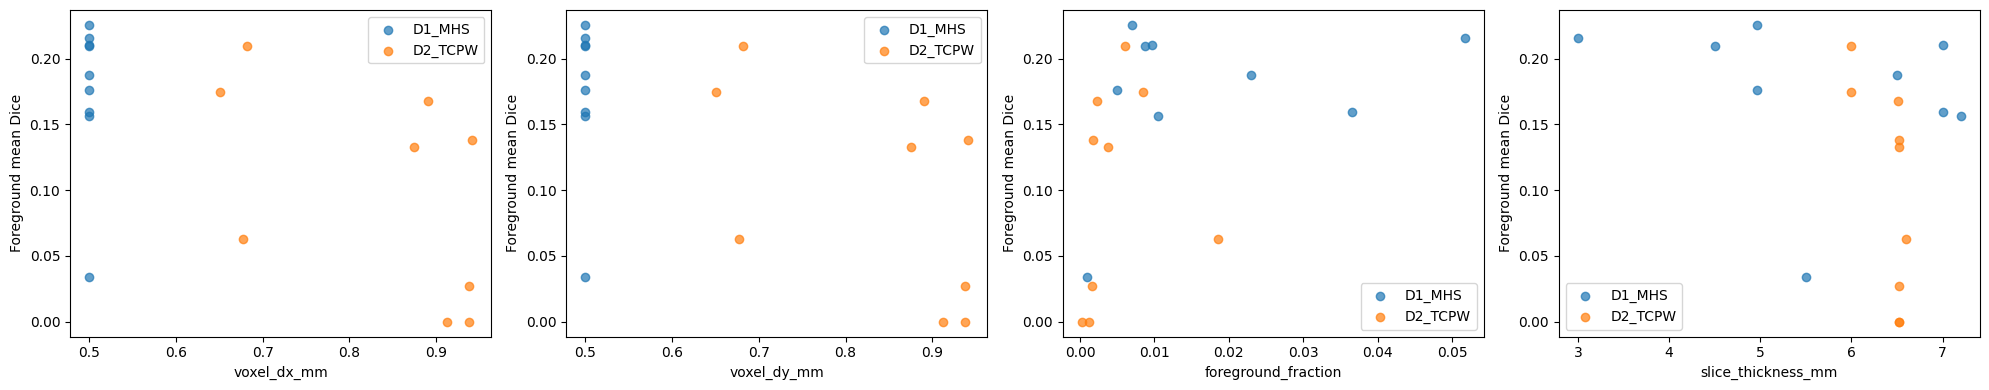

In [ ]:
import os
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr


def compute_case_covariates(case, site_name):
    img_nii = nib.load(case["image_path"])
    img_nii = nib.as_closest_canonical(img_nii)
    img_vol = img_nii.get_fdata().astype(np.float32)
    mask_vol = load_combined_mask(img_nii, case["label_paths"])

    spacing = img_nii.header.get_zooms()
    fg_fraction = float(np.mean(mask_vol > 0))
    n_structures_present = sum(1 for p in case["label_paths"].values() if p is not None)

    nonzero = img_vol[img_vol > np.percentile(img_vol, 5)]
    mean_intensity = float(np.mean(nonzero)) if nonzero.size else float("nan")
    std_intensity = float(np.std(nonzero)) if nonzero.size else float("nan")

    contrast_cv = std_intensity / mean_intensity if mean_intensity else float("nan")

    return {
        "case_id": case["case_id"],
        "site": site_name,
        "sequence_used": case["sequence"],
        "voxel_dx_mm": spacing[0] if len(spacing) > 0 else np.nan,
        "voxel_dy_mm": spacing[1] if len(spacing) > 1 else np.nan,
        "slice_thickness_mm": spacing[2] if len(spacing) > 2 else np.nan,
        "in_plane_shape_0": img_vol.shape[0],
        "in_plane_shape_1": img_vol.shape[1],
        "mean_intensity": mean_intensity,
        "std_intensity": std_intensity,
        "contrast_cv": contrast_cv,
        "foreground_fraction": fg_fraction,
        "n_structures_present": n_structures_present,
    }


def build_covariate_table():
    rows = []
    for site_dir, site_name in [(SITE_A_DIR, SITE_A_NAME),
                                 (SITE_B_DIR, SITE_B_NAME)]:
        cases = discover_cases(site_dir)
        for case in cases:
            rows.append(compute_case_covariates(case, site_name))
    return pd.DataFrame(rows)


def main():
    metrics_path = os.path.join(OUTPUT_DIR, "per_case_metrics_all.csv")
    if not os.path.exists(metrics_path):
        raise FileNotFoundError(
            f"{metrics_path} not found. Run the experiment cell first."
        )
    df_metrics = pd.read_csv(metrics_path)
    # failure analysis
    df_metrics = df_metrics[(df_metrics.experiment == FAILURE_ANALYSIS_EXPERIMENT) &
                            (df_metrics.seed == SEEDS[0])]
    df_metrics = df_metrics.drop(columns=["experiment", "seed", "eval_set"])
    df_covariates = build_covariate_table()

    df = df_metrics.merge(df_covariates, on=["case_id", "site"], how="inner")

    # --- 1. Site-level comparison of covariates (domain shift check) ---
    covariate_cols = [
        "voxel_dx_mm", "voxel_dy_mm", "slice_thickness_mm",
        "in_plane_shape_0", "in_plane_shape_1",
        "mean_intensity", "std_intensity", "contrast_cv",
        "foreground_fraction", "n_structures_present",
    ]
    print("=== Mean covariate values per site (domain shift check) ===")
    print(df.groupby("site")[covariate_cols].mean().T)
    print()

    print("=== MRI sequence used per site (protocol differences) ===")
    print(df.groupby(["site", "sequence_used"]).size().unstack(fill_value=0))
    print()

    # --- 2. Correlate covariates with performance (across ALL cases) ---
    print("=== Spearman correlation: covariate vs dice_foreground_mean ===")
    corr_rows = []
    for col in covariate_cols:
        valid = df[[col, "dice_foreground_mean"]].dropna()
        if len(valid) < 3:
            continue
        rho, pval = spearmanr(valid[col], valid["dice_foreground_mean"])
        corr_rows.append({"covariate": col, "spearman_rho": rho, "p_value": pval})
    corr_df = pd.DataFrame(corr_rows).sort_values("spearman_rho", key=abs,
                                                    ascending=False)
    print(corr_df.to_string(index=False))

    corr_out = os.path.join(OUTPUT_DIR, "covariate_correlations.csv")
    corr_df.to_csv(corr_out, index=False)
    full_out = os.path.join(OUTPUT_DIR, "per_case_metrics_with_covariates.csv")
    df.to_csv(full_out, index=False)

    # --- 3. Scatter plots for the top covariates ---
    top_covariates = corr_df["covariate"].head(4).tolist()
    fig, axes = plt.subplots(1, len(top_covariates), figsize=(5 * len(top_covariates), 4))
    if len(top_covariates) == 1:
        axes = [axes]
    for ax, col in zip(axes, top_covariates):
        for site_name, sub in df.groupby("site"):
            ax.scatter(sub[col], sub["dice_foreground_mean"], label=site_name, alpha=0.7)
        ax.set_xlabel(col)
        ax.set_ylabel("Foreground mean Dice")
        ax.legend()
    plt.tight_layout()
    plot_path = os.path.join(OUTPUT_DIR, "failure_analysis_scatter.png")
    plt.savefig(plot_path, dpi=150)
    print(f"\n[failure_analysis] scatter plots saved to: {plot_path}")
    print(f"[failure_analysis] full table saved to: {full_out}")
    print(f"[failure_analysis] correlation table saved to: {corr_out}")


if __name__ == "__main__":
    main()

In [ ]:
"""
MISSING-LABEL AUDIT + EVALUATION-ONLY CORRECTION
  1. counts, per site, which patients have no label file for each structure
  2. lists the affected patients, and shows whether they are test patients
  3. re-scores saved per-patient results with those organs EXCLUDED for the affected patients
     (a score against a label that does not exist is not a real score) and shows before vs after
  4. writes a corrected CSV feed it to the per-organ analysis cell

It does NOT repair TRAINING: models were still trained with those structures as background.
"""
import os
import glob
import numpy as np
import pandas as pd

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
RESULTS_PATTERN = "per_case_metrics_all*.csv"
UNAVAILABLE_ORGANS = ["ut", "ov"]


CHECK_IDS = ["D2-015", "D2-071", "D2-076", "D2-078"]   # patients that scored 0 uterus Dice under every model
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")

ST2ORGAN = {st: LABEL_MAP[cid] for st, cid in STRUCTURES_OF_INTEREST.items()}
ORGAN_COLS = {o: f"dice_{o}" for o in ST2ORGAN.values()}


def locate_results():
    hits = glob.glob(os.path.join(DRIVE_ROOT, "**", RESULTS_PATTERN), recursive=True)
    good = []
    for h in sorted(hits, key=os.path.getmtime, reverse=True):
        if "labelled_only" in os.path.basename(h):
            continue
        try:
            exps = set(pd.read_csv(h, usecols=["experiment"])["experiment"])
        except Exception:
            continue
        print(("  USE  " if {"A_only", "B_only", "pooled"} <= exps else "  skip ") + h + f"   {sorted(exps)}")
        if {"A_only", "B_only", "pooled"} <= exps:
            good.append(h)
    if not good:
        raise FileNotFoundError("No per-patient results file with A_only, B_only and pooled found on Drive.")
    return good[0]


def label_availability():
    rows = []
    for site_name, site_dir in [(SITE_A_NAME, SITE_A_DIR), (SITE_B_NAME, SITE_B_DIR)]:
        for c in discover_cases(site_dir):
            row = {"site": site_name, "case_id": c["case_id"]}
            for st in STRUCTURES_OF_INTEREST:
                row[st] = c["label_paths"].get(st) is not None
            rows.append(row)
    return pd.DataFrame(rows)


def run_audit():
    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", 30)
    path = locate_results()
    print("\nresults file:", path)
    df = pd.read_csv(path)
    avail = label_availability()
    sts = list(STRUCTURES_OF_INTEREST)

    print("\n=== Patients with a label file for each structure (pipeline view: ANY rater, T2 patients) ===")
    summ = avail.groupby("site")[sts].agg(["sum", "count"])
    print(summ)
    print("\n=== Patients with NO file for structures that should exist for every subject ===")
    missing = set()
    for st in UNAVAILABLE_ORGANS:
        for site, g in avail.groupby("site"):
            ids = sorted(g.loc[~g[st], "case_id"])
            print(f"  {site} {ST2ORGAN[st]:12s}: {len(ids):2d} patient(s) {ids}")
            missing |= {(i, ST2ORGAN[st]) for i in ids}

    test_ids = set(df["case_id"])
    hit = sorted((i, o) for i, o in missing if i in test_ids)
    print(f"\n=== Of these, TEST patients in your results ({len(hit)}) ===")
    for i, o in hit:
        print(f"  {i}: no {o} label")
    if not hit:
        print("  none - the saved test scores do not involve a missing label")

    print("\n=== The patients that scored ~0 uterus Dice under every model ===")
    for i in CHECK_IDS:
        r = avail[avail.case_id == i]
        if r.empty:
            print(f"  {i}: not in the T2 patient list"); continue
        vals = df[df.case_id == i].groupby("experiment")["dice_uterus"].mean().round(2).to_dict()
        print(f"  {i}: label files {{k: bool(v) for k, v in r.iloc[0][sts].items()}}   uterus Dice per model {vals}")

    # ---------- re-score: exclude (patient, organ) pairs whose label does not exist ----------
    fixed = df.copy()
    for i, o in missing:
        fixed.loc[fixed.case_id == i, ORGAN_COLS[o]] = np.nan
    cols = list(ORGAN_COLS.values())
    fixed["dice_foreground_mean"] = fixed[cols].mean(axis=1, skipna=True)

    def table(d):
        return d.groupby(["experiment", "eval_set"])[cols + ["dice_foreground_mean"]].mean().round(3)
    n_before = df.groupby(["experiment", "eval_set"])[cols].count()
    n_after = fixed.groupby(["experiment", "eval_set"])[cols].count()
    print("\n=== Mean Dice per organ: BEFORE (missing label = background) ===")
    print(table(df))
    print("\n=== Mean Dice per organ: AFTER (organs without a label excluded for those patients) ===")
    print(table(fixed))
    print("\n=== Patients per metric: before -> after ===")
    print(n_before.astype(str) + " -> " + n_after.astype(str))

    out = os.path.join(os.path.dirname(path), os.path.basename(path).replace(".csv", "_labelled_only.csv"))
    fixed.to_csv(out, index=False)
    avail.to_csv(os.path.join(os.path.dirname(path), "label_availability_by_patient.csv"), index=False)
    print("\nwritten:", out)
    print("          label_availability_by_patient.csv")
    print("-> run the per-organ analysis on the *_labelled_only.csv file (set RESULTS_CSV to its path).")
    return avail, fixed


df_label_availability, df_corrected = run_audit()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
  USE  /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/per_case_metrics_all-2.csv   ['A_only', 'B_only', 'pooled']
  skip /content/drive/MyDrive/Colab Notebooks/endometriosis/old results/per_case_metrics_all.csv   ['cross_site', 'pooled']

results file: /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/per_case_metrics_all-2.csv
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient

In [ ]:
 """
PART 2 RE-ANALYSIS FROM SAVED RESULTS
Re-analyses the rater experiment
  1. audits label files that exist but are empty
  2. rebuilds the patient flow
  3. checks that the trained models used exactly the expected patients (
  4. prints the number of test patients behind EVERY metric, per organ   (r2: 4 vs 5)
  5. reports paired differences with exact tests and no CI for n < 10    (CI vs Wilcoxon)
"""
import os
import glob
import json
import hashlib
import itertools
import re
import numpy as np
import pandas as pd
import nibabel as nib
from scipy.stats import friedmanchisquare, wilcoxon

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
SEED = 42
SPLIT_VAL_FRACTION = 0.15
SPLIT_TEST_FRACTION = 0.20
EVAL_SLICE_MODE = "union"
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")

CLASS_IDS = list(range(1, NUM_CLASSES))
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")
EMPTY_UTERUS_MEANS_MISSING = True      # a uterus file that exists but is all zeros = "not annotated"
EMPTY_FILES = set()                    # (case_id, rater, structure): file exists but has no foreground


def locate_results():
    hits = glob.glob(os.path.join(DRIVE_ROOT, "**", "rater_model_results.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("rater_model_results.csv not found on Drive (it is written by Part 2 into "
                                "<your folder>/rater_part2/).")
    hits = sorted(hits, key=os.path.getmtime, reverse=True)
    if len(hits) > 1:
        print(f"[warn] {len(hits)} copies found; using the newest: {hits[0]}\n       others: {hits[1:]}")
    folder = os.path.dirname(hits[0])
    rr = os.path.join(folder, "rater_vs_rater_test_cases.csv")
    if not os.path.isfile(rr):
        raise FileNotFoundError(f"{rr} not found next to rater_model_results.csv")
    return folder, hits[0], rr


def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rater_files, rater):
    return {st: rater_files.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def audit_empty_files(files):
    """Find label files that EXIST but contain no foreground """
    EMPTY_FILES.clear()
    counts = {}
    for cid, per_rater in files.items():
        for r, structs in per_rater.items():
            for st, path in structs.items():
                if not np.asarray(nib.load(path).dataobj).any():
                    EMPTY_FILES.add((cid, r, st))
                    counts[(r, st)] = counts.get((r, st), 0) + 1
    print("\n=== Label files that exist but are EMPTY (all zeros) ===")
    if not counts:
        print("  none")
    for (r, st), n in sorted(counts.items()):
        print(f"  {r} {st}: {n} file(s)")
    print("  rule: an empty uterus file = not annotated (excluded); an empty ovary/endometrioma file "
          "= empty annotation, exactly like a missing file for a patient the rater annotated.")


def has_uterus(files, cid, rater):
    if "ut" not in files[cid].get(rater, {}):
        return False
    return not (EMPTY_UTERUS_MEANS_MISSING and (cid, rater, "ut") in EMPTY_FILES)


def split_cases_three_way(cases, val_fraction, test_fraction, seed):
    rng = np.random.RandomState(seed)
    idx = np.arange(len(cases))
    rng.shuffle(idx)
    n = len(idx)
    n_test = max(1, int(round(n * test_fraction)))
    n_val = max(1, int(round(n * val_fraction)))
    if n - n_test - n_val < 1:
        raise ValueError(f"Only {n} cases.")
    pick = lambda ids: [cases[i] for i in sorted(ids)]
    return pick(idx[n_test + n_val:]), pick(idx[n_test:n_test + n_val]), pick(idx[:n_test])


def _bci(x, n_boot=5000, seed=0):
    rng = np.random.RandomState(seed)
    return np.percentile([rng.choice(x, len(x)).mean() for _ in range(n_boot)], [2.5, 97.5])


def signflip_p(diffs, n_mc=20000, seed=0):
    diffs = np.asarray(diffs, float)
    obs = abs(diffs.mean())
    mag = np.abs(diffs[diffs != 0])
    n = len(mag)
    if n == 0:
        return np.nan
    if n <= 15:
        signs = np.array(list(itertools.product([-1.0, 1.0], repeat=n)))
        sims = np.abs((signs * mag).sum(1) / len(diffs))
    else:
        rng = np.random.RandomState(seed)
        sims = np.abs((rng.choice([-1.0, 1.0], size=(n_mc, n)) * mag).sum(1) / len(diffs))
    return float((sims >= obs - 1e-12).mean())


def paired_report(label, d):
    d = np.asarray(d, float)
    d = d[~np.isnan(d)]
    n = len(d)
    if n < 3:
        print(f"  {label}: only {n} paired patients - skipped")
        return
    nz = int((d != 0).sum())
    p_w = wilcoxon(d).pvalue if nz > 0 else np.nan
    p_f = signflip_p(d)
    min_p = 2.0 / 2 ** nz if nz else np.nan
    print(f"  {label}: n={n}  mean {d.mean():+.3f}  median {np.median(d):+.3f}   "
          f"Wilcoxon p={p_w:.3f}   sign-flip p={p_f:.3f}   (smallest attainable p with {nz} non-zero differences: {min_p:.4f})")
    if n <= 12:
        print("      per-patient differences: " + " ".join(f"{x:+.3f}" for x in sorted(d)))
    if n >= 10:
        lo, hi = _bci(d)
        print(f"      95% CI of the mean (percentile bootstrap): [{lo:+.3f}, {hi:+.3f}]")
    else:
        print("      95% CI not reported: with n < 10 a percentile bootstrap interval is too narrow")


def own_advantage(df, r, col):
    own = df[(df.train_rater == r) & (df.eval_rater == r)].set_index(["seed", "case_id"])[col]
    oth = df[(df.train_rater == r) & (df.eval_rater != r)].groupby(["seed", "case_id"])[col].mean()
    return (own - oth).dropna().values


def summarize_rater_model(df, df_rr, train_raters):
    pd.set_option("display.width", 220)
    pd.set_option("display.max_columns", 30)
    fg = "dice_foreground_mean"
    ut = f"dice_{LABEL_MAP[STRUCTURES_OF_INTEREST['ut']]}"
    dcols = [f"dice_{LABEL_MAP[c]}" for c in CLASS_IDS]
    other_cols = [c for c in dcols if c != ut]

    print("\n=== Test patients actually behind each metric (non-missing values), per cell ===")
    print("    (rows: model trained on / evaluated against; a metric is missing where that rater has no label for the organ)")
    print(df.groupby(["train_rater", "eval_rater"])[dcols + [fg]].count())

    print("\n=== UTERUS Dice: trained on (rows) vs evaluated against (columns) ===")
    print(df.pivot_table(index="train_rater", columns="eval_rater", values=ut, aggfunc="mean").round(3))
    print("--- n patients per cell ---")
    print(df.pivot_table(index="train_rater", columns="eval_rater", values=ut, aggfunc="count").fillna(0).astype(int))

    print("\n=== OVARIES / ENDOMETRIOMA Dice (mean per cell) ===")
    print(df.groupby(["train_rater", "eval_rater"])[other_cols].mean().round(3))

    print("\n=== Foreground Dice (CAUTION: the organs averaged differ between cells, e.g. no uterus label "
          "-> ovary/endometrioma only; use the per-organ tables for conclusions) ===")
    print(df.pivot_table(index="train_rater", columns="eval_rater", values=fg, aggfunc="mean").round(3))

    own_m = df[df.train_rater == df.eval_rater]
    oth_m = df[df.train_rater != df.eval_rater]
    print("\n=== Per organ: model vs own rater / vs other raters / rater vs rater (mean Dice, n) ===")
    tab = pd.DataFrame({
        "model vs own": own_m[dcols].mean(), "n": own_m[dcols].count(),
        "model vs other": oth_m[dcols].mean(), "n ": oth_m[dcols].count(),
        "rater vs rater": df_rr[dcols].mean(), "n  ": df_rr[dcols].count()})
    print(tab.round(3))

    for col, name in [(ut, "UTERUS (primary: available for every counted patient)"),
                      (fg, "FOREGROUND mean (organ set varies between patients - secondary)")]:
        print(f"\n=== Own-rater advantage, {name} ===")
        print("    own rater minus mean of the other annotating raters, per patient")
        for r in train_raters:
            paired_report(f"model {r}", own_advantage(df, r, col))

    print("\n=== Does the TRAINING rater matter? UTERUS Dice, same patients, same evaluation rater ===")
    for ev in sorted(df.eval_rater.unique()):
        w = (df[df.eval_rater == ev].pivot_table(index=["seed", "case_id"], columns="train_rater",
             values=ut).reindex(columns=train_raters).dropna())
        if len(w) < 3:
            print(f"  evaluated vs {ev}: only {len(w)} patients - skipped"); continue
        if len(train_raters) == 2:
            paired_report(f"evaluated vs {ev}: {train_raters[0]}-trained minus {train_raters[1]}-trained",
                          (w[train_raters[0]] - w[train_raters[1]]).values)
        else:
            p = friedmanchisquare(*[w[t].values for t in train_raters]).pvalue
            print(f"  evaluated vs {ev}: Friedman p={p:.4f} (n={len(w)})")

    print("\n=== Rater vs rater on the TEST patients (same space and slices as the model scores) ===")
    print(df_rr.groupby("pair")[[ut, fg]].agg(["mean", "count"]).round(3))

# ---------------------------------------------------------------- run
def run_reanalysis():
    pd.set_option("display.width", 220)
    pd.set_option("display.max_columns", 30)
    folder, res_path, rr_path = locate_results()
    print("results folder:", folder)
    df = pd.read_csv(res_path)
    df_rr = pd.read_csv(rr_path)
    train_raters = sorted(df["train_rater"].unique())
    print(f"models trained on: {train_raters}; test patients in the results: {df['case_id'].nunique()}")

    cases_a = discover_cases(SITE_A_DIR)
    files = {c["case_id"]: case_rater_files(c) for c in cases_a}
    raters = sorted({r for f in files.values() for r in f})

    # ---- 1. empty files ------------------------------------------------------------
    audit_empty_files(files)

    # ---- 2. patient flow ----------------------------------------------------------
    A_tr, A_va, A_te = split_cases_three_way(cases_a, SPLIT_VAL_FRACTION, SPLIT_TEST_FRACTION, SEED)
    te_ids = {c["case_id"] for c in A_te}
    extra = set(df["case_id"]) - te_ids
    print(f"\n=== Check: results use the test patients of the rebuilt split: "
          f"{'OK' if not extra else 'MISMATCH - ' + str(sorted(extra))} ===")
    if extra:
        print("   The split rebuilt here differs from the one used for the run (different fractions, seed or "
              "case list?). Counts below may not describe your run.")

    all_have = lambda lst: [c for c in lst if all(has_uterus(files, c["case_id"], r) for r in train_raters)]
    tr_used, va_used = all_have(A_tr), all_have(A_va)
    print(f"\n=== Patient flow (seed {SEED}) ===")
    for name, lst in [("train", A_tr), ("val", A_va), ("test", A_te)]:
        per = ", ".join(f"{r}: {sum(has_uterus(files, c['case_id'], r) for c in lst)}" for r in raters)
        line = f"  {name:5s} {len(lst):3d} patients | uterus label from -> {per}"
        if name == "train":
            line += f" | used for training (uterus label from ALL of {train_raters}): {len(tr_used)}"
        if name == "val":
            line += f" | used for validation: {len(va_used)}"
        print(line)
    print("  test patients are never filtered; each metric uses the test patients that have that organ "
          "for that rater (see the per-metric counts below).")
    flow = pd.DataFrame([{"split": n, "case_id": c["case_id"],
                          **{f"uterus_{r}": has_uterus(files, c["case_id"], r) for r in raters}}
                         for n, lst in [("train", A_tr), ("val", A_va), ("test", A_te)] for c in lst])
    flow["used_for_training"] = flow.apply(lambda x: x.split in ("train", "val") and all(x[f"uterus_{r}"] for r in train_raters), axis=1)
    flow.to_csv(os.path.join(folder, f"patient_flow_seed{SEED}_reanalysis.csv"), index=False)

    # ---- 3a. did the models train on exactly these patients?  ----
    print("\n=== Check: were the saved models trained on exactly these patients? ===")
    try:
        epochs = NUM_EPOCHS
    except NameError:
        epochs = None
    for r in train_raters:
        found = None
        for tag in ["uterus-rule-v2", "uterus-rule-v3"]:
            sig = hashlib.md5(json.dumps([r, sorted(c["case_id"] for c in tr_used),
                                          sorted(c["case_id"] for c in va_used),
                                          EVAL_SLICE_MODE, epochs, tag]).encode()).hexdigest()[:8]
            if glob.glob(os.path.join(folder, f"rows_{r}_seed{SEED}_{sig}.csv")):
                found = (tag, sig)
        print(f"  model {r}: " + (f"MATCH ({found[0]}, signature {found[1]}) - trained on the {len(tr_used)} train / "
                                  f"{len(va_used)} val patients above" if found else
                                  "no signature match (settings such as NUM_EPOCHS may differ; cannot verify)"))

    # ---- 3b. do the saved scores follow the uterus rule? -------------------------------
    ut = f"dice_{LABEL_MAP[STRUCTURES_OF_INTEREST['ut']]}"
    has = df.apply(lambda x: has_uterus(files, x["case_id"], x["eval_rater"]), axis=1)
    print("\n=== Check: uterus scored only against raters who annotated it ===")
    print(f"  uterus Dice present although the rater has no uterus label: {int((~has & df[ut].notna()).sum())}  (should be 0)")
    print(f"  uterus Dice missing although the rater has a uterus label:  {int((has & df[ut].isna()).sum())}  "
          f"(0 unless both prediction and label are empty)")

    # ---- 4+5. summary with per-organ n and small-sample statistics ----------------------
    df.groupby(["train_rater", "eval_rater"]).count().to_csv(os.path.join(folder, "metric_counts_reanalysis.csv"))
    summarize_rater_model(df, df_rr, train_raters)
    print("\nfiles written next to the results:", folder)


run_reanalysis()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
results folder: /content/drive/MyDrive/Colab Notebooks/endometriosis/rater_part2
models trained on: ['r2', 'r3']; test patients in the results: 9
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none

In [ ]:
  import os
  for pid in ["D2-041","D2-046","D2-052","D2-054","D2-057","D2-071","D2-076","D2-077"]:
      print(pid, sorted(os.listdir(os.path.join(SITE_B_DIR, pid))))

D2-041 ['D2-041_T1.nii.gz', 'D2-041_T1FS.nii.gz', 'D2-041_T2.nii.gz', 'D2-041_T2FS.nii.gz', 'D2-041_cy.nii.gz', 'D2-041_em.nii.gz']
D2-046 ['D2-046_T1.nii.gz', 'D2-046_T2.nii.gz', 'D2-046_T2FS.nii.gz', 'D2-046_ov.nii.gz']
D2-052 ['D2-052_T1.nii.gz', 'D2-052_T1FS.nii.gz', 'D2-052_T2.nii.gz', 'D2-052_T2FS.nii.gz', 'D2-052_ov.nii.gz']
D2-054 ['D2-054_T1.nii.gz', 'D2-054_T1FS.nii.gz', 'D2-054_T2.nii.gz', 'D2-054_T2FS.nii.gz', 'D2-054_em.nii.gz', 'D2-054_ov.nii.gz']
D2-057 ['D2-057_T1.nii.gz', 'D2-057_T1FS.nii.gz', 'D2-057_T2.nii.gz', 'D2-057_T2FS.nii.gz', 'D2-057_ov.nii.gz']
D2-071 ['D2-071_T1.nii.gz', 'D2-071_T2.nii.gz', 'D2-071_T2FS.nii.gz', 'D2-071_em.nii.gz']
D2-076 ['D2-076_T1FS.nii.gz', 'D2-076_T2.nii.gz', 'D2-076_T2FS.nii.gz', 'D2-076_cy.nii.gz', 'D2-076_ov.nii.gz']
D2-077 ['D2-077_T1.nii.gz', 'D2-077_T1FS.nii.gz', 'D2-077_T2.nii.gz', 'D2-077_T2FS.nii.gz', 'D2-077_em.nii.gz']


In [ ]:
   import glob
   for pid in ["D2-071", "D2-076", "D2-041"]:
       print(pid, [p for p in glob.glob(DATA_ROOT + "/**/*" + pid + "*", recursive=True)])

D2-071 ['/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_T2.nii.gz', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_T2FS.nii.gz', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_em.nii.gz', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_T1.nii.gz']
D2-076 ['/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-076', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-076/D2-076_ov.nii.gz', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-076/D2-076_T2FS.nii.gz', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-076/D2-076_T2.nii.gz', '/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-076/D2-076_T1FS.nii.gz', '/content/drive/MyDriv

In [ ]:

paths = {
    "T2": "/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_T2.nii.gz",
    "T2FS": "/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_T2FS.nii.gz",
    "Endometrioma mask": "/content/drive/MyDrive/Colab Notebooks/endometriosis/UT-EndoMRI/D2_TCPW/D2-071/D2-071_em.nii.gz",
    #"Cyst mask": "path/to/cy_mask.nii.gz",
}

for name, path in paths.items():
    img = nib.load(path)
    data = np.asarray(img.dataobj)

    print(f"\n{name}")
    print("Shape:", img.shape)
    print("Voxel spacing:", img.header.get_zooms()[:3])
    print("Affine:\n", img.affine)
    print("Non-zero voxels:", np.count_nonzero(data))


T2
Shape: (400, 400, 68)
Voxel spacing: (np.float32(0.9125), np.float32(0.9125), np.float32(6.525373))
Affine:
 [[-9.11980271e-01  3.07939835e-02 -1.30866340e-03  1.98591339e+02]
 [-3.07945274e-02 -9.11964178e-01  3.87560725e-02  2.04994797e+02]
 [-1.40227135e-11  5.42268949e-03  6.52525806e+00 -2.44401703e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Non-zero voxels: 8153590

T2FS
Shape: (320, 320, 44)
Voxel spacing: (np.float32(0.78125), np.float32(0.78125), np.float32(6.0))
Affine:
 [[-7.78517783e-01  6.52812570e-02 -1.20330020e-03  1.47271729e+02]
 [-6.52810410e-02 -7.78504014e-01  3.56357321e-02  1.49999939e+02]
 [ 2.31595273e-04  4.63693403e-03  5.99989414e+00 -2.32106705e+02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  1.00000000e+00]]
Non-zero voxels: 3624052

Endometrioma mask
Shape: (320, 320, 44)
Voxel spacing: (np.float32(0.78125), np.float32(0.78125), np.float32(6.0))
Affine:
 [[-7.78517783e-01  6.52812570e-02 -1.20330008e-03  1.47271729e

In [ ]:
"""
HOW MUCH OF THE TRAINING DATA HAD MISSING LABELS?
"""
import os
import glob
import pandas as pd

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
AVAIL_NAME = "label_availability_by_patient.csv"
SPLITS_NAME = "splits-2.csv"
SEED = 42
ORGANS = {"ut": "uterus", "ov": "ovaries", "em": "endometrioma"}
# -------------------------------------------------------------------------


def newest(name):
    hits = sorted(glob.glob(os.path.join(DRIVE_ROOT, "**", name), recursive=True), key=os.path.getmtime, reverse=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found on Drive")
    if len(hits) > 1:
        print(f"[warn] {len(hits)} copies of {name}; using the newest: {hits[0]}")
    return hits[0]


avail_path, splits_path = newest(AVAIL_NAME), newest(SPLITS_NAME)
print("availability:", avail_path, "\nsplits      :", splits_path)
avail = pd.read_csv(avail_path)
splits = pd.read_csv(splits_path)
if "seed" in splits.columns:
    splits = splits[splits["seed"] == SEED]

# site key in splits.csv is 'A'/'B'; availability uses the site names (D1_MHS / D2_TCPW): A = first, B = second
names = sorted(avail["site"].unique())
site_key = {"A": names[0], "B": names[1]}
splits["site"] = splits["site"].map(site_key)
df = splits.merge(avail, on=["site", "case_id"], how="left")
unmatched = int(df["ut"].isna().sum())
if unmatched:
    print(f"[warn] {unmatched} patients in splits.csv are not in the availability table (no T2 / no labels)")
df = df.dropna(subset=["ut"])
for st in ORGANS:
    df[f"no_{st}"] = ~df[st].astype(bool)

rows = []
for (site, split), g in df.groupby(["site", "split"]):
    rows.append({"site": site, "split": split, "patients": len(g),
                 **{f"no_{ORGANS[st]}": int(g[f"no_{st}"].sum()) for st in ORGANS}})
t = pd.DataFrame(rows).sort_values(["site", "split"])
print("\n=== Patients WITHOUT a label file, per site and split ===")
print(t.to_string(index=False))

print("\n=== Exposure of each model's TRAINING + VALIDATION data (train and val patients together) ===")
sets = {"A_only": [site_key["A"]], "B_only": [site_key["B"]], "pooled": [site_key["A"], site_key["B"]]}
exp = []
for model, sites in sets.items():
    g = df[df.site.isin(sites) & df.split.isin(["train", "val"])]
    row = {"model": model, "train+val patients": len(g)}
    for st in ORGANS:
        n = int(g[f"no_{st}"].sum())
        row[f"no {ORGANS[st]}"] = f"{n} ({100 * n / max(len(g), 1):.0f}%)"
    exp.append(row)
exp = pd.DataFrame(exp)
print(exp.to_string(index=False))
print("\nTEST patients affected (excluded per organ in the corrected evaluation):")
for st in ["ut", "ov"]:
    ids = df[(df.split == "test") & df[f"no_{st}"]]
    print(f"  {ORGANS[st]:9s}: " + (", ".join(f"{r.case_id}" for r in ids.itertuples()) or "none"))

out = os.path.join(os.path.dirname(avail_path), "label_exposure_table.csv")
exp.to_csv(out, index=False)
t.to_csv(os.path.join(os.path.dirname(avail_path), "label_missing_by_split.csv"), index=False)
print("\nsaved:", out, "and label_missing_by_split.csv")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
availability: /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/label_availability_by_patient.csv 
splits      : /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/splits-2.csv

=== Patients WITHOUT a label file, per site and split ===
   site split  patients  no_uterus  no_ovaries  no_endometrioma
 D1_MHS  test         9          0           2                1
 D1_MHS train        29          1           4                6
 D1_MHS   val         7          1           0                3
D2_TCPW  test         9          2           2                6
D2_TCPW train        29          4           7               25
D2_TCPW   val         7          2           2                6

=== Exposure of each model's TRAINING + VALIDATION data (train and val patients together) ===
 model  train+val patients no uterus no ovaries no endometrioma

In [ ]:
"""
  Table 1  Dice per organ x training set x test site (mean, 95% CI, n)          -> RQ1 (and raw material for RQ2/RQ3)
  Table 2  RQ2 generalisation gaps and RQ3 pooling comparisons (+ Holm over the 12 RQ3 tests)
  Table 3  data and label availability, training exposure, eligible test patients
  Table 4  pairwise rater agreement (3D Dice)

Statistics (stated in every caption below):
  * unit of analysis = PATIENT (seeds averaged per patient first)
  * CI of a mean: Student-t (CI_METHOD="t", default) or percentile bootstrap (CI_METHOD="bootstrap");
    means are clipped to [0, 1] for display. With n < 10 a percentile bootstrap is too narrow -> default is t.
  * paired differences: same patients in both models; exact Wilcoxon signed-rank test (needs >= 5 pairs)
  * RQ2 gaps compare DIFFERENT patients (in-site vs other site) -> Welch interval, no p-value
  * Holm correction over the 12 RQ3 comparisons (4 comparisons x 3 organs)
"""
import os
import glob
import itertools
import numpy as np
import pandas as pd
from scipy import stats

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
RESULTS_CSV = None
SPLITS_NAME = "splits-2.csv"
SEED = 42
CI_METHOD = "t"               # "t" or "bootstrap"
FLOOR = 0.10                  # mean Dice below this is marked * (near the floor: differences not interpretable)
MAIN_ORGAN = "uterus"         # the organ shown in the main-text version of Table 2
N_BOOT = 10000
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")

EXPS = ["A_only", "B_only", "pooled"]
TESTS = ["A_test", "B_test"]
ORGANS = ["uterus", "ovaries", "endometrioma"]


# ------------------------------------------------------------ locate files
def newest(pattern, exclude=(), must=None, quiet=False):
    hits = sorted(glob.glob(os.path.join(DRIVE_ROOT, "**", pattern), recursive=True),
                  key=os.path.getmtime, reverse=True)
    hits = [h for h in hits if not any(e in os.path.basename(h) for e in exclude)]
    if must:
        hits = [h for h in hits if must(h)]
    if hits and not quiet and len(hits) > 1:
        print(f"[note] {len(hits)} candidates for {pattern}; using the newest: {hits[0]}")
    return hits[0] if hits else None


def has_experiments(path):
    try:
        return {"A_only", "B_only", "pooled"} <= set(pd.read_csv(path, usecols=["experiment"])["experiment"])
    except Exception:
        return False


def locate_results():
    if RESULTS_CSV:
        return RESULTS_CSV, "labelled_only" in os.path.basename(RESULTS_CSV)
    p = newest("per_case_metrics_all*labelled_only*.csv", exclude=("ut-ov-em",), must=has_experiments)
    if p:
        return p, True
    print("\n[WARNING] no label-corrected results file found - falling back to the ORIGINAL file, in which a missing "
          "uterus/ovary label counts as background. Run the missing-label audit cell first for final tables.\n")
    p = newest("per_case_metrics_all*.csv", exclude=("labelled_only",), must=has_experiments)
    if not p:
        raise FileNotFoundError("No per-patient results file with A_only, B_only and pooled found on Drive.")
    return p, False


# ---------------------------------------------------------------- statistics
def patient_level(df):
    cols = [f"dice_{o}" for o in ORGANS] + ["dice_foreground_mean"]
    return df.groupby(["experiment", "eval_set", "case_id"], as_index=False)[cols].mean()


def vals(pl, exp, es, organ):
    col = "dice_foreground_mean" if organ == "foreground_mean" else f"dice_{organ}"
    return pl[(pl.experiment == exp) & (pl.eval_set == es)].set_index("case_id")[col].dropna()


def ci_of_mean(x, clip=True):
    x = np.asarray(x, float)
    n = len(x)
    if n < 3:
        return np.nan, np.nan
    if CI_METHOD == "bootstrap":
        rng = np.random.RandomState(0)
        m = x[rng.randint(0, n, size=(N_BOOT, n))].mean(1)
        lo, hi = np.percentile(m, [2.5, 97.5])
    else:
        h = stats.t.ppf(0.975, n - 1) * x.std(ddof=1) / np.sqrt(n)
        lo, hi = x.mean() - h, x.mean() + h
    return (max(lo, 0.0), min(hi, 1.0)) if clip else (lo, hi)


def ci_paired(d):
    d = np.asarray(d, float)
    n = len(d)
    if n < 3:
        return np.nan, np.nan
    if CI_METHOD == "bootstrap":
        rng = np.random.RandomState(0)
        m = d[rng.randint(0, n, size=(N_BOOT, n))].mean(1)
        return tuple(np.percentile(m, [2.5, 97.5]))
    h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return d.mean() - h, d.mean() + h


def welch_ci(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3 or len(y) < 3:
        return np.nan, np.nan
    vx, vy = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    se = np.sqrt(vx + vy)
    dfw = (vx + vy) ** 2 / (vx ** 2 / (len(x) - 1) + vy ** 2 / (len(y) - 1)) if se > 0 else 1
    h = stats.t.ppf(0.975, dfw) * se
    d = x.mean() - y.mean()
    return d - h, d + h


def holm(p):
    p = np.asarray(p, float)
    out, ok = np.full(len(p), np.nan), np.where(~np.isnan(p))[0]
    prev = 0.0
    for rank, i in enumerate(ok[np.argsort(p[ok])]):
        prev = max(prev, (len(ok) - rank) * p[i])
        out[i] = min(1.0, prev)
    return out


def fmt_ci(m, lo, hi, n, star=True):
    if n == 0:
        return "n/a (n=0)"
    s = f"{m:.3f} [{lo:.3f}, {hi:.3f}] (n={n})" if not np.isnan(lo) else f"{m:.3f} (n={n})"
    return s + (" *" if star and m < FLOOR else "")


# ----------------------------------------------------------------- tables
def table1(pl):
    long, wide = [], []
    for exp in EXPS:
        row = {("", "Trained on"): exp}
        for organ in ORGANS + ["foreground_mean"]:
            for es in TESTS:
                x = vals(pl, exp, es, organ).values
                m = x.mean() if len(x) else np.nan
                lo, hi = ci_of_mean(x)
                long.append({"organ": organ, "trained_on": exp, "test_set": es, "mean": m, "ci_low": lo,
                             "ci_high": hi, "n_patients": len(x), "near_floor": bool(len(x) and m < FLOOR)})
                row[(organ, es)] = fmt_ci(m, lo, hi, len(x), star=organ != "foreground_mean")
        wide.append(row)
    w = pd.DataFrame(wide).set_index(("", "Trained on"))
    w.columns = pd.MultiIndex.from_tuples(w.columns)
    w.index.name = "Trained on"
    return pd.DataFrame(long), w


COMPARISONS = [("pooled", "A_only", "A_test", "pooled - A_only on A_test (in-site model)"),
               ("pooled", "B_only", "B_test", "pooled - B_only on B_test (in-site model)"),
               ("pooled", "A_only", "B_test", "pooled - A_only on B_test (cross-site model)"),
               ("pooled", "B_only", "A_test", "pooled - B_only on A_test (cross-site model)")]


def table2(pl):
    rows = []
    for organ in ORGANS:                                                    # RQ2: gaps, different patients
        for exp, ins, cross, lab in [("A_only", "A_test", "B_test", "A -> B (A_only: A_test minus B_test)"),
                                     ("B_only", "B_test", "A_test", "B -> A (B_only: B_test minus A_test)")]:
            x, y = vals(pl, exp, ins, organ).values, vals(pl, exp, cross, organ).values
            if len(x) < 3 or len(y) < 3:
                continue
            lo, hi = welch_ci(x, y)
            rows.append({"question": "RQ2", "comparison": lab, "organ": organ, "mean_diff": x.mean() - y.mean(),
                         "ci_low": lo, "ci_high": hi, "n": f"{len(x)} vs {len(y)}",
                         "p_wilcoxon": np.nan, "p_holm_12": np.nan,
                         "near_floor": bool(max(x.mean(), y.mean()) < FLOOR)})
    rq3 = []
    for a, b, es, lab in COMPARISONS:                                       # RQ3: paired, same patients
        for organ in ORGANS:
            d = (vals(pl, a, es, organ) - vals(pl, b, es, organ)).dropna().values
            if len(d) < 3:
                continue
            lo, hi = ci_paired(d)
            p = stats.wilcoxon(d).pvalue if len(d) >= 5 and (d != 0).any() else np.nan
            rq3.append({"question": "RQ3", "comparison": lab, "organ": organ, "mean_diff": d.mean(),
                        "ci_low": lo, "ci_high": hi, "n": f"{len(d)} pairs", "p_wilcoxon": p,
                        "near_floor": bool(max(vals(pl, a, es, organ).mean(), vals(pl, b, es, organ).mean()) < FLOOR)})
    adj = holm([r["p_wilcoxon"] for r in rq3])
    for r, a_ in zip(rq3, adj):
        r["p_holm_12"] = a_
    return pd.DataFrame(rows + rq3)


def table3(df, avail_path, splits_path):
    avail = pd.read_csv(avail_path)
    splits = pd.read_csv(splits_path)
    if "seed" in splits.columns:
        splits = splits[splits["seed"] == SEED]
    names = sorted(avail["site"].unique())
    key = {"A": names[0], "B": names[1]}
    splits["site"] = splits["site"].map(key)
    m = splits.merge(avail, on=["site", "case_id"], how="left").dropna(subset=["ut"])
    sts = {"ut": "uterus", "ov": "ovaries", "em": "endometrioma"}
    rows = []
    for site, g in m.groupby("site"):
        tv = g[g.split.isin(["train", "val"])]
        te = g[g.split == "test"]
        row = {"site": site, "T2 patients": len(g),
               "train / val / test": f"{(g.split == 'train').sum()} / {(g.split == 'val').sum()} / {(g.split == 'test').sum()}"}
        for st, o in sts.items():
            row[f"{o}: with label"] = f"{int(g[st].astype(bool).sum())}/{len(g)}"
        for st, o in sts.items():
            nmiss = int((~tv[st].astype(bool)).sum())
            row[f"{o}: no label in train+val"] = f"{nmiss} ({100 * nmiss / max(len(tv), 1):.0f}%)"
        for st, o in sts.items():
            row[f"{o}: test patients with label"] = f"{int(te[st].astype(bool).sum())}/{len(te)}"
        rows.append(row)
    sites_table = pd.DataFrame(rows).set_index("site").T
    exp = []
    for model, ss in {"A_only": [key["A"]], "B_only": [key["B"]], "pooled": [key["A"], key["B"]]}.items():
        g = m[m.site.isin(ss) & m.split.isin(["train", "val"])]
        r = {"model": model, "train+val patients": len(g)}
        for st, o in sts.items():
            n = int((~g[st].astype(bool)).sum())
            r[f"no {o} label"] = f"{n} ({100 * n / len(g):.0f}%)"
        exp.append(r)
    return sites_table, pd.DataFrame(exp).set_index("model")


def table4(pair_path):
    p = pd.read_csv(pair_path)
    g = p.dropna(subset=["dice"]).groupby(["organ", "pair"])["dice"].agg(["mean", "std", "median", "count"])
    g.columns = ["mean Dice", "std", "median", "n patients"]
    return g.round(3)


# ----------------------------------------------------------------- output
def latex(df, caption, label):
    def esc(s):
        return str(s).replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("*", r"$^{*}$")
    d = df.reset_index() if df.index.name or isinstance(df.index, pd.MultiIndex) else df
    cols = [" / ".join(x for x in c if x) if isinstance(c, tuple) else str(c) for c in d.columns]
    lines = [r"\begin{table}[ht]", r"\centering", r"\small", rf"\caption{{{caption}}}", rf"\label{{{label}}}",
             r"\begin{tabular}{" + "l" * len(cols) + "}", r"\hline",
             " & ".join(esc(c) for c in cols) + r" \\", r"\hline"]
    for _, r in d.iterrows():
        lines.append(" & ".join(esc(v) for v in r.values) + r" \\")
    lines += [r"\hline", r"\end{tabular}", r"\end{table}"]
    return "\n".join(lines)


def run_final_tables():
    pd.set_option("display.width", 250)
    pd.set_option("display.max_columns", 40)
    pd.set_option("display.max_colwidth", 60)
    path, corrected = locate_results()
    folder = os.path.dirname(path)
    out = os.path.join(folder, "final_tables")
    os.makedirs(out, exist_ok=True)
    print(("RESULTS FILE (label-corrected): " if corrected else "RESULTS FILE (ORIGINAL, NOT CORRECTED): ") + path)
    df = pd.read_csv(path)
    pl = patient_level(df)
    seeds = df["seed"].nunique() if "seed" in df.columns else 1
    n_sites = df.groupby("eval_set")["case_id"].nunique().to_dict()
    print(f"seeds: {seeds}; test patients per site: {n_sites}; CI method: {CI_METHOD}\n")
    saved = {}

    t1_long, t1 = table1(pl)
    print("=" * 100, "\nTABLE 1  Dice per organ, by training set (rows) and test site (columns): mean [95% CI] (n patients)")
    print("A = D1_MHS, B = D2_TCPW. * = mean Dice < %.2f (near floor). Organs without a label are excluded per patient.\n" % FLOOR)
    print(t1.drop(columns=["foreground_mean"], level=0).to_string())
    saved["table1"] = t1_long

    t2 = table2(pl)
    print("\n" + "=" * 100, "\nTABLE 2  RQ2 gaps (different patients, Welch CI) and RQ3 paired comparisons (same patients)")
    show = t2.copy()
    show["95% CI"] = show.apply(lambda r: f"[{r.ci_low:+.3f}, {r.ci_high:+.3f}]" if not np.isnan(r.ci_low) else "n/a", axis=1)
    cols = ["question", "comparison", "organ", "mean_diff", "95% CI", "n", "p_wilcoxon", "p_holm_12", "near_floor"]
    print(f"\n--- main text: {MAIN_ORGAN} ---")
    print(show[show.organ == MAIN_ORGAN][cols].round(3).to_string(index=False))
    print("\n--- all organs (appendix) ---")
    print(show[cols].round(3).to_string(index=False))
    print(f"\nHolm correction is over the {int(t2.p_wilcoxon.notna().sum())} RQ3 tests that have a p-value; "
          f"smallest raw p = {t2.p_wilcoxon.min():.3f}, smallest adjusted p = {t2.p_holm_12.min():.3f}.")
    saved["table2"] = t2

    avail_path = newest("label_availability_by_patient.csv")
    splits_path = newest(SPLITS_NAME)
    if avail_path and splits_path:
        sites_t, exp_t = table3(df, avail_path, splits_path)
        print("\n" + "=" * 100, "\nTABLE 3  Data and label availability (T2 patients)")
        print(sites_t.to_string())
        print("\nTraining + validation exposure per model (patients without a label file):")
        print(exp_t.to_string())
        saved["table3_sites"] = sites_t.reset_index()
        saved["table3_exposure"] = exp_t.reset_index()
    else:
        print("\n[Table 3 skipped] needs label_availability_by_patient.csv (missing-label audit cell) and", SPLITS_NAME)

    pair_path = newest("pairwise_dice.csv")
    if pair_path:
        t4 = table4(pair_path)
        print("\n" + "=" * 100, "\nTABLE 4  Pairwise rater agreement, 3D Dice (patients that both raters annotated; uterus excludes missing files)")
        print(t4.to_string())
        saved["table4"] = t4.reset_index()
    else:
        print("\n[Table 4 skipped] needs pairwise_dice.csv (pairwise rater-agreement notebook).")

    # appendix: uncorrected vs corrected means
    raw_path = newest("per_case_metrics_all*.csv", exclude=("labelled_only",), must=has_experiments, quiet=True)
    if corrected and raw_path:
        raw = patient_level(pd.read_csv(raw_path))
        rows = []
        for organ in ORGANS:
            for exp in EXPS:
                for es in TESTS:
                    a, b = vals(raw, exp, es, organ), vals(pl, exp, es, organ)
                    rows.append({"organ": organ, "trained_on": exp, "test_set": es,
                                 "uncorrected mean": round(a.mean(), 3), "n_uncorrected": len(a),
                                 "corrected mean": round(b.mean(), 3), "n_corrected": len(b)})
        app = pd.DataFrame(rows)
        print("\n" + "=" * 100, "\nAPPENDIX  uncorrected (missing label = background) vs corrected means")
        print(app.to_string(index=False))
        saved["appendix_uncorrected_vs_corrected"] = app

    # save everything
    for name, t in saved.items():
        t.to_csv(os.path.join(out, f"{name}.csv"), index=False)
    caps = {"table1": ("Dice per organ by training set and test site (patient-level mean, 95\\% CI, number of eligible patients).", "tab:dice"),
            "table2": ("Cross-site gaps (RQ2) and pooled-versus-single-site comparisons (RQ3).", "tab:rq")}
    for name, (cap, lab) in caps.items():
        if name in saved:
            src = t1.drop(columns=["foreground_mean"], level=0) if name == "table1" else saved[name].round(3)
            open(os.path.join(out, f"{name}.tex"), "w").write(latex(src, cap, lab))
    try:
        with pd.ExcelWriter(os.path.join(out, "final_tables.xlsx")) as xw:
            for name, t in saved.items():
                t.to_excel(xw, sheet_name=name[:31], index=False)
        print("\nExcel workbook saved.")
    except Exception as e:
        print(f"\n[info] Excel workbook not written ({e}); the CSV files are complete.")
    print("\nAll tables saved to:", out)
    return saved


final_tables = run_final_tables()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
RESULTS FILE (label-corrected): /content/drive/MyDrive/Colab Notebooks/endometriosis/new results/per_case_metrics_all-2_labelled_only.csv
seeds: 1; test patients per site: {'A_test': 9, 'B_test': 9}; CI method: t

TABLE 1  Dice per organ, by training set (rows) and test site (columns): mean [95% CI] (n patients)
A = D1_MHS, B = D2_TCPW. * = mean Dice < 0.10 (near floor). Organs without a label are excluded per patient.

                                uterus                                                   ovaries                                                endometrioma                              
                                A_test                      B_test                        A_test                        B_test                        A_test                        B_test
Trained on                                                               

In [ ]:
"""
MODEL vs RATER AGREEMENT WITH THE SAME 2D PROTOCOL AS THE MAIN RESULTS
"""
import os
import re
import glob
import itertools
import numpy as np
import pandas as pd
import nibabel as nib
import torch
from skimage.transform import resize

# ------------------------------- settings -------------------------------
DRIVE_ROOT = "/content/drive/MyDrive"
SPLITS_NAME = "splits-2.csv"
SEED = 42
MODEL_FILES = {"A_only": "unet_A_only_seed42.pt",            # main experiments
               "B_only": "unet_B_only_seed42.pt",
               "pooled": "unet_pooled_seed42-2.pt"}
RATER_MODEL_GLOBS = {"r2-trained": "unet_rater_r2_seed42_*.pt",   # rater-specific models (Part 2), optional
                     "r3-trained": "unet_rater_r3_seed42_*.pt"}
# -------------------------------------------------------------------------

from google.colab import drive
drive.mount("/content/drive")

CLASS_IDS = list(range(1, NUM_CLASSES))
ORGANS = [LABEL_MAP[c] for c in CLASS_IDS]
_RATER_RE = re.compile(r"_(?P<st>[a-z]+)_(?P<rater>r\d+)\.nii\.gz$")
EMPTY_FILES = set()


def newest(pattern):
    hits = sorted(glob.glob(os.path.join(DRIVE_ROOT, "**", pattern), recursive=True), key=os.path.getmtime, reverse=True)
    return hits[0] if hits else None


def case_rater_files(case):
    pdir = os.path.join(case["site_dir"], case["case_id"])
    out = {}
    for st in STRUCTURES_OF_INTEREST:
        for p in glob.glob(os.path.join(pdir, f"{case['case_id']}_{st}_r*.nii.gz")):
            m = _RATER_RE.search(os.path.basename(p))
            if m and m.group("st") == st:
                out.setdefault(m.group("rater"), {})[st] = p
    return out


def rater_label_paths(rf, rater):
    return {st: rf.get(rater, {}).get(st) for st in STRUCTURES_OF_INTEREST}


def audit_empty(files_all):
    EMPTY_FILES.clear()
    for cid, per in files_all.items():
        for r, sts in per.items():
            for st, p in sts.items():
                if not np.asarray(nib.load(p).dataobj).any():
                    EMPTY_FILES.add((cid, r, st))


def organ_ok(cid, files, rater, organ):
    if rater not in files:
        return False
    if organ == "uterus":
        return "ut" in files[rater] and (cid, rater, "ut") not in EMPTY_FILES
    return True


def dice_class(a, b):
    d = a.sum() + b.sum()
    return np.nan if d == 0 else 2.0 * np.logical_and(a, b).sum() / d


def to_ms(slice_2d):
    return resize(slice_2d, (IMAGE_SIZE, IMAGE_SIZE), order=0, preserve_range=True, anti_aliasing=False)


def score_2d(pred_ms, ref_native):
    """Main-protocol score. pred_ms: [n, S, S] labels in model space; ref_native: reference mask on the image grid."""
    per = {c: [] for c in CLASS_IDS}
    for i in range(ref_native.shape[SLICE_AXIS]):
        r = np.take(ref_native, i, axis=SLICE_AXIS)
        if np.count_nonzero(r) < MIN_FOREGROUND_PIXELS:
            continue
        rr = to_ms(r)
        for c in CLASS_IDS:
            per[c].append(dice_class(pred_ms[i] == c, rr == c))
    return {c: (np.nan if not v or np.all(np.isnan(v)) else float(np.nanmean(v))) for c, v in per.items()}


def native_to_ms(vol):
    return np.stack([to_ms(np.take(vol, i, axis=SLICE_AXIS)) for i in range(vol.shape[SLICE_AXIS])]).astype(np.int8)


def load_model(path, device):
    model = SmallUNet(1, NUM_CLASSES, BASE_CHANNELS).to(device)
    ck = torch.load(path, map_location=device, weights_only=False)
    model.load_state_dict(ck["model_state"] if "model_state" in ck else ck)
    model.eval()
    return model


@torch.no_grad()
def predict_volume(model, case, device, batch=16):
    img = nib.as_closest_canonical(nib.load(case["image_path"])).get_fdata().astype(np.float32)
    n = img.shape[SLICE_AXIS]
    sl = [resize(normalize_intensity(np.take(img, i, axis=SLICE_AXIS)), (IMAGE_SIZE, IMAGE_SIZE), order=1,
                 preserve_range=True, anti_aliasing=True) for i in range(n)]
    x = torch.from_numpy(np.stack(sl)).float().unsqueeze(1)
    out = [torch.argmax(model(x[k:k + batch].to(device)), dim=1).cpu() for k in range(0, n, batch)]
    return torch.cat(out).numpy().astype(np.int8)


def test_cases_site_a():
    splits = pd.read_csv(newest(SPLITS_NAME))
    if "seed" in splits.columns:
        splits = splits[splits["seed"] == SEED]
    ids = set(splits[(splits["site"] == "A") & (splits["split"] == "test")]["case_id"])
    cases = [c for c in discover_cases(SITE_A_DIR) if c["case_id"] in ids]
    missing = ids - {c["case_id"] for c in cases}
    if missing:
        print(f"[warn] test patients not in the T2 case list: {sorted(missing)}")
    return cases


def run_model_vs_rater(predict_fn=None, models=None):
    cases = test_cases_site_a()
    files_all = {c["case_id"]: case_rater_files(c) for c in cases}
    audit_empty(files_all)
    print(f"site-A test patients: {len(cases)}; with >= 1 rater: {sum(bool(f) for f in files_all.values())}")

    if models is None:
        models = {}
        dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        for name, fn in MODEL_FILES.items():
            p = newest(fn)
            print(("found " if p else "MISSING ") + f"{name}: {fn}")
            if p:
                models[name] = load_model(p, dev)
        for name, pat in RATER_MODEL_GLOBS.items():
            p = newest(pat)
            print(("found " if p else "MISSING ") + f"{name}: {pat}")
            if p:
                models[name] = load_model(p, dev)
        predict_fn = lambda name, case: predict_volume(models[name], case, dev)
    rows, rr_rows = [], []
    for c in cases:
        cid, files = c["case_id"], files_all[c["case_id"]]
        if not files:
            continue
        image_nii = nib.as_closest_canonical(nib.load(c["image_path"]))
        refs = {r: load_combined_mask(image_nii, rater_label_paths(files, r)) for r in files}
        preds = {name: predict_fn(name, c) for name in models}
        for name, pv in preds.items():
            for r, ref in refs.items():
                sc = score_2d(pv, ref)
                row = {"model": name, "reference_rater": r, "case_id": cid}
                for cls in CLASS_IDS:
                    o = LABEL_MAP[cls]
                    row[o] = sc[cls] if organ_ok(cid, files, r, o) else np.nan
                rows.append(row)
        for ra, rb in itertools.combinations(sorted(files), 2):          # rater vs rater, same protocol, both directions
            a2b = score_2d(native_to_ms(refs[rb]), refs[ra])
            b2a = score_2d(native_to_ms(refs[ra]), refs[rb])
            row = {"pair": f"{ra}-{rb}", "case_id": cid}
            for cls in CLASS_IDS:
                o = LABEL_MAP[cls]
                ok = organ_ok(cid, files, ra, o) and organ_ok(cid, files, rb, o)
                v = np.nan if not ok or (np.isnan(a2b[cls]) and np.isnan(b2a[cls])) else np.nanmean([a2b[cls], b2a[cls]])
                row[o] = v
            rr_rows.append(row)
    df, rr = pd.DataFrame(rows), pd.DataFrame(rr_rows)

    pd.set_option("display.width", 220)
    pd.set_option("display.max_columns", 30)
    print("\n=== Model vs each rater (2D protocol): mean Dice per organ, and n patients ===")
    models_ = list(df["model"].unique())
    refs_ = sorted(df["reference_rater"].unique())
    for o in ORGANS:
        t = pd.DataFrame(index=models_, columns=refs_, dtype=object)
        for mname in models_:
            for r in refs_:
                x = df[(df.model == mname) & (df.reference_rater == r)][o].dropna()
                t.loc[mname, r] = f"{x.mean():.3f} (n={len(x)})" if len(x) else "n/a (n=0)"
        print(f"\n--- {o} ---")
        print(t.to_string())
    print("\n=== Rater vs rater on the SAME test patients (2D protocol, both directions averaged) ===")
    g = rr.melt(id_vars=["pair", "case_id"], var_name="organ", value_name="dice").dropna().groupby(["organ", "pair"])["dice"].agg(["mean", "count"]).round(3)
    print(g.to_string())
    print("\n=== Summary per organ: model (all references pooled) vs rater pairs (same test patients) ===")
    summ = []
    for o in ORGANS:
        for name in df["model"].unique():
            x = df[df.model == name][o].dropna()
            summ.append({"organ": o, "who": f"model {name}", "mean 2D Dice": round(x.mean(), 3) if len(x) else np.nan, "n (patient-reference pairs)": len(x)})
        y = rr[o].dropna()
        summ.append({"organ": o, "who": "rater vs rater", "mean 2D Dice": round(y.mean(), 3) if len(y) else np.nan, "n (patient-reference pairs)": len(y)})
    S = pd.DataFrame(summ)
    print(S.to_string(index=False))

    out = os.path.join(os.path.dirname(newest(SPLITS_NAME)), "model_vs_rater_2d")
    os.makedirs(out, exist_ok=True)
    df.to_csv(os.path.join(out, "model_vs_rater_per_patient.csv"), index=False)
    rr.to_csv(os.path.join(out, "rater_vs_rater_per_patient.csv"), index=False)
    S.to_csv(os.path.join(out, "summary_model_vs_rater.csv"), index=False)
    print("\nsaved to:", out)
    return df, rr, S


if os.environ.get("ENDOMRI_SKIP_RUN") != "1":
    df_mvr, df_rvr, summary_mvr = run_model_vs_rater()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[warn] D1-002: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-005: missing label(s) for ['ut'] -> treating as background for that structure
[warn] D1-006: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-011: none of ['D1-011_T2.nii.gz'] found. Files actually present: ['D1-011_T1FS.nii.gz', 'D1-011_em_r1.nii.gz', 'D1-011_em_r2.nii.gz', 'D1-011_em_r3.nii.gz', 'D1-011_ov_r1.nii.gz', 'D1-011_ut_r3.nii.gz']
[warn] D1-011: skipping patient (no usable sequence)
[warn] D1-012: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-013: missing label(s) for ['em'] -> treating as background for that structure
[warn] D1-014: none of ['D1-014_T2.nii.gz'] found. Files actually present: ['D1-014_T1FS.nii.gz', 'D1-014_em_r3.nii.gz', 'D1-014_ut_r3.nii.gz']
[warn] D1-014: skippi

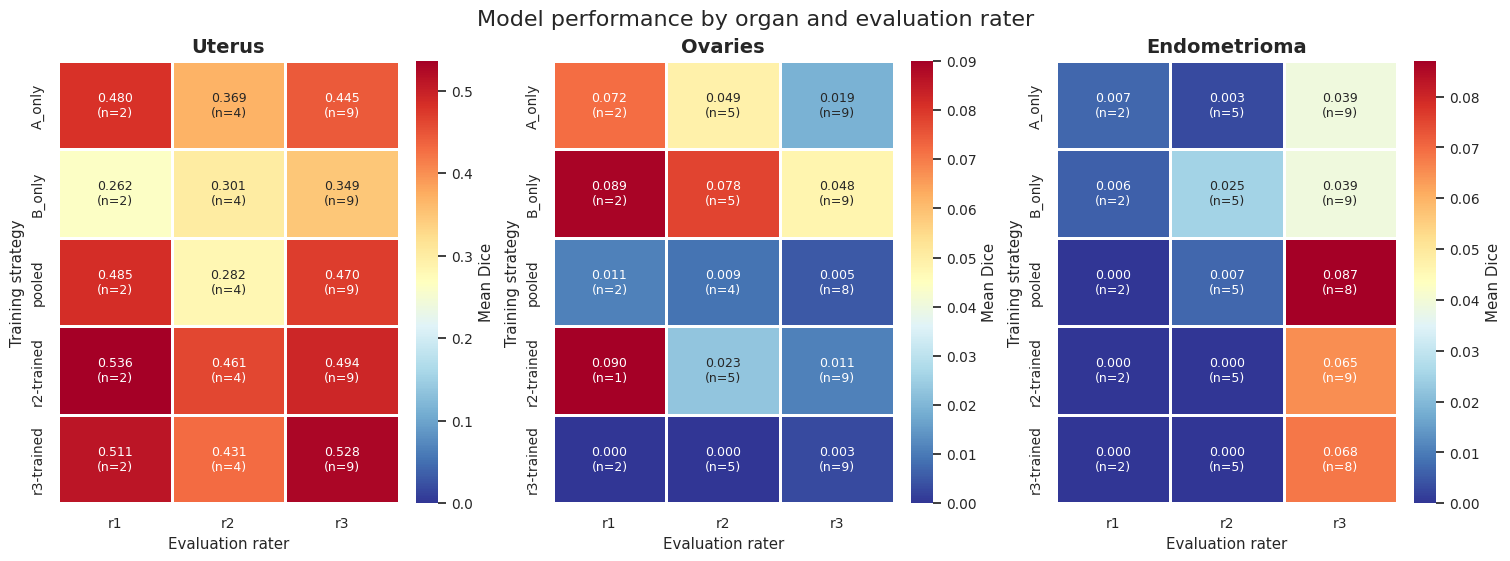

In [ ]:


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

models = ["A_only", "B_only", "pooled", "r2-trained", "r3-trained"]
raters = ["r1", "r2", "r3"]

data = {
    "Uterus": {
        "dice": [
            [0.480, 0.369, 0.445],
            [0.262, 0.301, 0.349],
            [0.485, 0.282, 0.470],
            [0.536, 0.461, 0.494],
            [0.511, 0.431, 0.528],
        ],
        "n": [
            [2, 4, 9],
            [2, 4, 9],
            [2, 4, 9],
            [2, 4, 9],
            [2, 4, 9],
        ],
    },
    "Ovaries": {
        "dice": [
            [0.072, 0.049, 0.019],
            [0.089, 0.078, 0.048],
            [0.011, 0.009, 0.005],
            [0.090, 0.023, 0.011],
            [0.000, 0.000, 0.003],
        ],
        "n": [
            [2, 5, 9],
            [2, 5, 9],
            [2, 4, 8],
            [1, 5, 9],
            [2, 5, 9],
        ],
    },
    "Endometrioma": {
        "dice": [
            [0.007, 0.003, 0.039],
            [0.006, 0.025, 0.039],
            [0.000, 0.007, 0.087],
            [0.000, 0.000, 0.065],
            [0.000, 0.000, 0.068],
        ],
        "n": [
            [2, 5, 9],
            [2, 5, 9],
            [2, 5, 8],
            [2, 5, 9],
            [2, 5, 8],
        ],
    },
}

sns.set_theme(style="white", font_scale=0.9)

fig, axes = plt.subplots(
    1, 3, figsize=(15, 5.5),
    constrained_layout=True
)

for ax, (organ, values) in zip(axes, data.items()):
    dice = np.array(values["dice"])
    counts = np.array(values["n"])

    # Show both Dice and sample size in each cell
    labels = np.empty(dice.shape, dtype=object)
    for i in range(len(models)):
        for j in range(len(raters)):
            labels[i, j] = (
                f"{dice[i, j]:.3f}\n(n={counts[i, j]})"
            )

    # Organ-specific scale preserves detail for low Dice scores
    vmax = dice.max()
    if vmax == 0:
        vmax = 1

    sns.heatmap(
        dice,
        ax=ax,
        annot=labels,
        fmt="",
        cmap="RdYlBu_r",
        vmin=0,
        vmax=vmax,
        linewidths=1,
        linecolor="white",
        xticklabels=raters,
        yticklabels=models,
        cbar_kws={"label": "Mean Dice"},
        annot_kws={"fontsize": 9}
    )

    ax.set_title(organ, fontsize=14, fontweight="bold")
    ax.set_xlabel("Evaluation rater")
    ax.set_ylabel("Training strategy")

fig.suptitle(
    "Model performance by organ and evaluation rater",
    fontsize=16
)

plt.savefig(
    "model_dice_heatmaps.png",
    dpi=300,
    bbox_inches="tight"
)

plt.savefig(
    "model_dice_heatmaps.pdf",
    bbox_inches="tight"
)

plt.show()



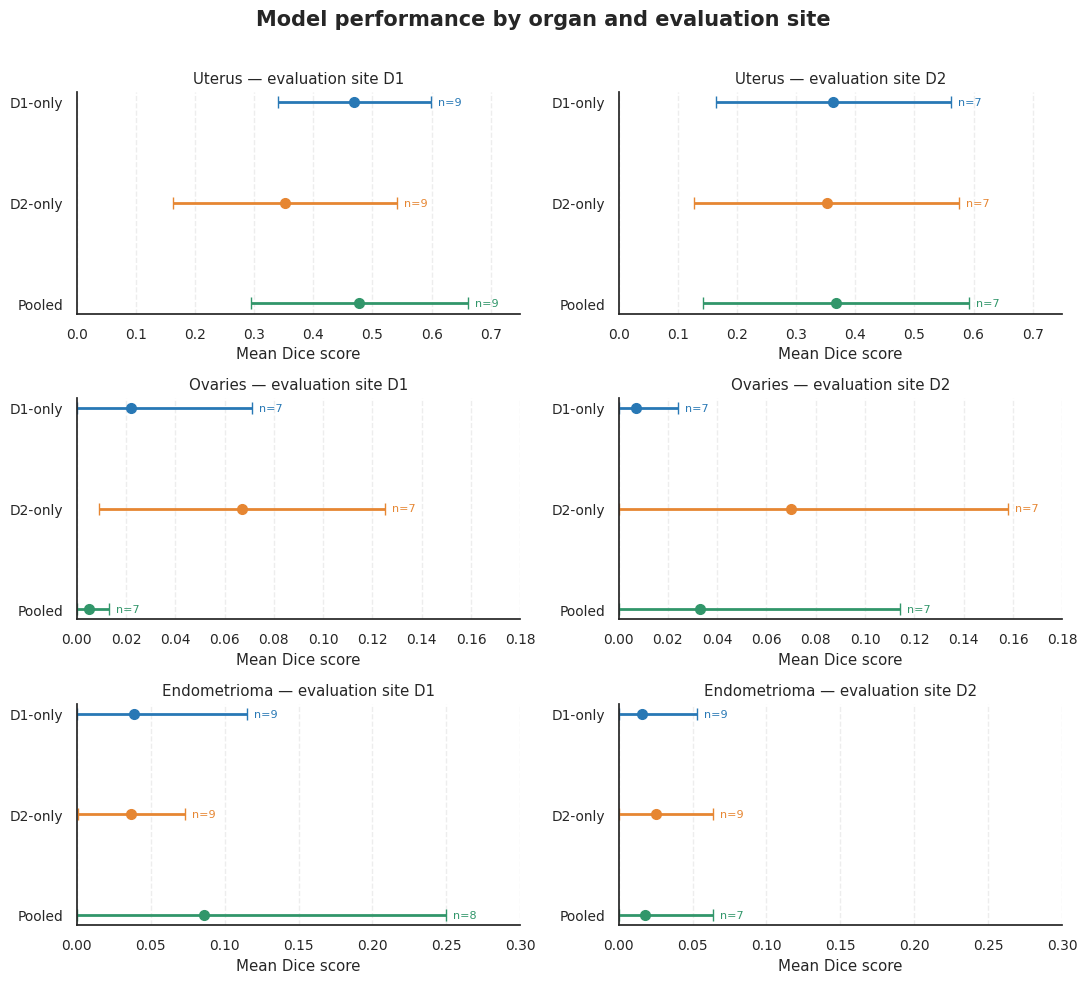

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Each entry: mean Dice, lower CI, upper CI, sample size
data = {
    "Uterus": {
        "D1": {
            "D1-only": (0.469, 0.340, 0.599, 9),
            "D2-only": (0.352, 0.162, 0.541, 9),
            "Pooled":  (0.478, 0.295, 0.662, 9),
        },
        "D2": {
            "D1-only": (0.363, 0.165, 0.562, 7),
            "D2-only": (0.352, 0.128, 0.576, 7),
            "Pooled":  (0.368, 0.143, 0.593, 7),
        },
    },
    "Ovaries": {
        "D1": {
            "D1-only": (0.022, 0.000, 0.071, 7),
            "D2-only": (0.067, 0.009, 0.125, 7),
            "Pooled":  (0.005, 0.000, 0.013, 7),
        },
        "D2": {
            "D1-only": (0.007, 0.000, 0.024, 7),
            "D2-only": (0.070, 0.000, 0.158, 7),
            "Pooled":  (0.033, 0.000, 0.114, 7),
        },
    },
    "Endometrioma": {
        "D1": {
            "D1-only": (0.039, 0.000, 0.115, 9),
            "D2-only": (0.037, 0.001, 0.073, 9),
            "Pooled":  (0.086, 0.000, 0.250, 8),
        },
        "D2": {
            "D1-only": (0.016, 0.000, 0.053, 9),
            "D2-only": (0.025, 0.000, 0.064, 9),
            "Pooled":  (0.018, 0.000, 0.064, 7),
        },
    },
}

models = ["D1-only", "D2-only", "Pooled"]

colors = {
    "D1-only": "#2878B5",
    "D2-only": "#E68632",
    "Pooled": "#31966A",
}

# Same x-scale for both sites within each organ
x_limits = {
    "Uterus": (0, 0.75),
    "Ovaries": (0, 0.18),
    "Endometrioma": (0, 0.30),
}

fig, axes = plt.subplots(
    nrows=3,
    ncols=2,
    figsize=(11, 10),
)

for row, organ in enumerate(data):
    for col, site in enumerate(["D1", "D2"]):
        ax = axes[row, col]

        for y, model in enumerate(models):
            mean, lower, upper, n = data[organ][site][model]

            # Asymmetric confidence interval error bars
            xerr = np.array([
                [mean - lower],
                [upper - mean],
            ])

            ax.errorbar(
                mean,
                y,
                xerr=xerr,
                fmt="o",
                color=colors[model],
                ecolor=colors[model],
                elinewidth=2,
                capsize=4,
                markersize=7,
            )

            # Sample size annotation
            xmax = x_limits[organ][1]
            ax.annotate(
                f"n={n}",
                (upper, y),
                xytext=(5, 0),
                textcoords="offset points",
                va="center",
                fontsize=8,
                color=colors[model],
            )

        ax.set_yticks(range(len(models)))
        ax.set_yticklabels(models)
        ax.invert_yaxis()

        ax.set_xlim(*x_limits[organ])
        ax.set_xlabel("Mean Dice score")
        ax.set_title(f"{organ} — evaluation site {site}")

        ax.grid(axis="x", linestyle="--", alpha=0.35)
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

fig.suptitle(
    "Model performance by organ and evaluation site",
    fontsize=15,
    fontweight="bold",
)

fig.tight_layout(rect=[0, 0, 1, 0.97])

fig.savefig(
    "dice_forest_plot.png",
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    "dice_forest_plot.pdf",
    bbox_inches="tight",
)

plt.show()


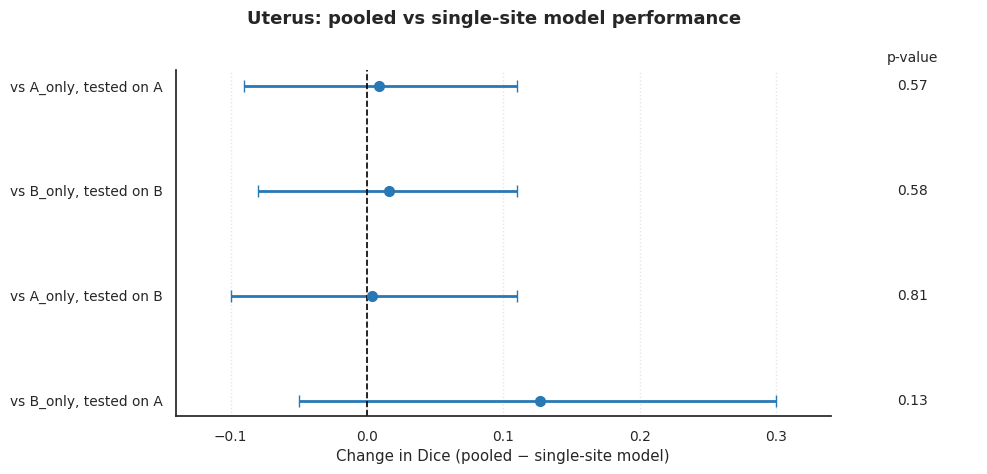

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

comparisons = [
    "vs A_only, tested on A",
    "vs B_only, tested on B",
    "vs A_only, tested on B",
    "vs B_only, tested on A",
]

change = np.array([0.009, 0.016, 0.004, 0.127])
lower = np.array([-0.09, -0.08, -0.10, -0.05])
upper = np.array([0.11, 0.11, 0.11, 0.30])
p_values = ["0.57", "0.58", "0.81", "0.13"]

y = np.arange(len(comparisons))

fig, (ax, ax_p) = plt.subplots(
    ncols=2,
    figsize=(10, 4.8),
    gridspec_kw={"width_ratios": [5, 1]},
    sharey=True,
)

# Asymmetric confidence interval lengths
xerr = np.vstack([
    change - lower,
    upper - change,
])

ax.errorbar(
    change,
    y,
    xerr=xerr,
    fmt="o",
    color="#2878B5",
    ecolor="#2878B5",
    elinewidth=2,
    capsize=4,
    markersize=7,
)

# Reference line: no difference between models
ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1.2,
)

ax.set_yticks(y)
ax.set_yticklabels(comparisons)
ax.invert_yaxis()

ax.set_xlabel(
    "Change in Dice (pooled − single-site model)"
)
ax.set_xlim(-0.14, 0.34)
ax.set_xticks([-0.1, 0.0, 0.1, 0.2, 0.3])

ax.grid(axis="x", linestyle=":", alpha=0.5)
ax.set_axisbelow(True)

# Separate p-value column
ax_p.set_xlim(0, 1)
ax_p.set_xticks([])
ax_p.set_title("p-value", fontsize=10)
ax_p.tick_params(
    axis="y",
    left=False,
    labelleft=False,
)

for i, p in enumerate(p_values):
    ax_p.text(
        0.5, i, p,
        ha="center",
        va="center",
        fontsize=10,
    )

# Clean appearance
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

for spine in ["top", "right", "left", "bottom"]:
    ax_p.spines[spine].set_visible(False)

fig.suptitle(
    "Uterus: pooled vs single-site model performance",
    fontsize=13,
    fontweight="bold",
)

fig.tight_layout()

fig.savefig(
    "uterus_pooled_comparison.png",
    dpi=300,
    bbox_inches="tight",
)
fig.savefig(
    "uterus_pooled_comparison.pdf",
    bbox_inches="tight",
)

plt.show()


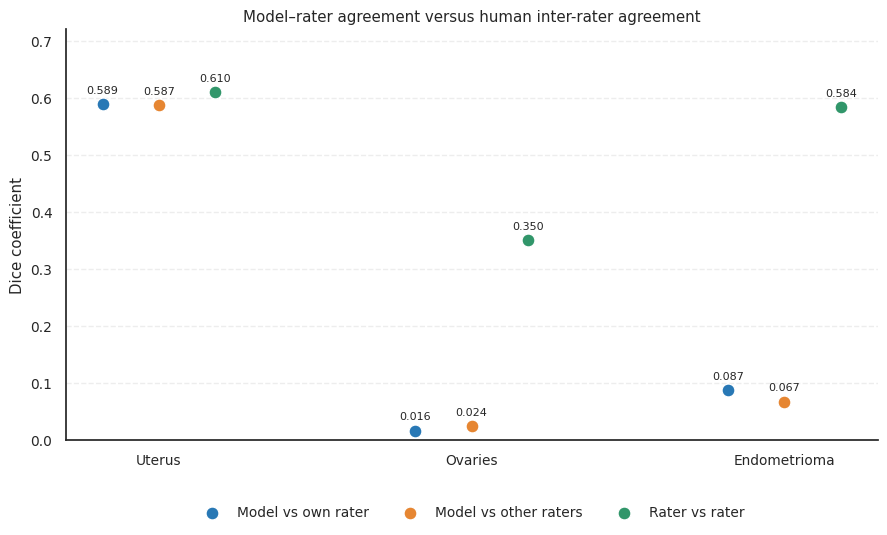

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

organs = ["Uterus", "Ovaries", "Endometrioma"]

data = {
    "Model vs own rater": [0.589, 0.016, 0.087],
    "Model vs other raters": [0.587, 0.024, 0.067],
    "Rater vs rater": [0.610, 0.350, 0.584],
}

colors = {
    "Model vs own rater": "#2878B5",
    "Model vs other raters": "#E68632",
    "Rater vs rater": "#31966A",
}

x = np.arange(len(organs))
offsets = [-0.18, 0, 0.18]

fig, ax = plt.subplots(figsize=(9, 5.5))

for (label, values), offset in zip(data.items(), offsets):
    ax.scatter(
        x + offset,
        values,
        s=85,
        label=label,
        color=colors[label],
        edgecolor="white",
        linewidth=0.8,
        zorder=3,
    )

    # Numerical values next to each marker
    for xi, yi in zip(x + offset, values):
        ax.annotate(
            f"{yi:.3f}",
            (xi, yi),
            xytext=(0, 8),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

ax.set_xticks(x)
ax.set_xticklabels(organs)
ax.set_ylabel("Dice coefficient")
ax.set_ylim(0, 0.72)
ax.set_title(
    "Model–rater agreement versus human inter-rater agreement"
)

ax.grid(axis="y", linestyle="--", alpha=0.35)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center",
          bbox_to_anchor=(0.5, -0.13), ncol=3)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig("agreement_comparison.png", dpi=300,
            bbox_inches="tight")
fig.savefig("agreement_comparison.pdf",
            bbox_inches="tight")
plt.show()


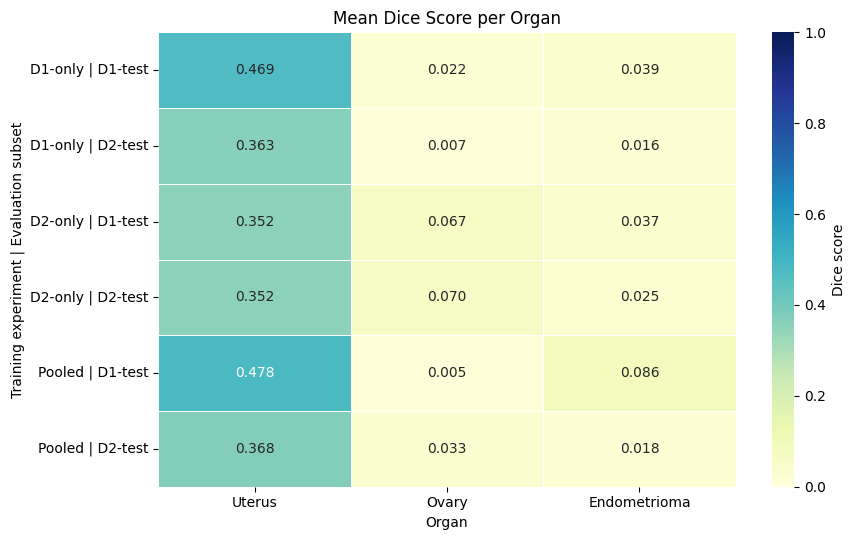

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dice scores
data = {
    "Uterus": [0.469, 0.363, 0.352, 0.352, 0.478, 0.368],
    "Ovary": [0.022, 0.007, 0.067, 0.070, 0.005, 0.033],
    "Endometrioma": [0.039, 0.016, 0.037, 0.025, 0.086, 0.018]
}

rows = [
    "D1-only | D1-test",
    "D1-only | D2-test",
    "D2-only | D1-test",
    "D2-only | D2-test",
    "Pooled | D1-test",
    "Pooled | D2-test"
]

df = pd.DataFrame(data, index=rows)

plt.figure(figsize=(9, 5.5))

sns.heatmap(
    df,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Dice score"}
)

plt.title("Mean Dice Score per Organ")
plt.xlabel("Organ")
plt.ylabel("Training experiment | Evaluation subset")
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig("dice_heatmap.png", dpi=300, bbox_inches="tight")

plt.show()

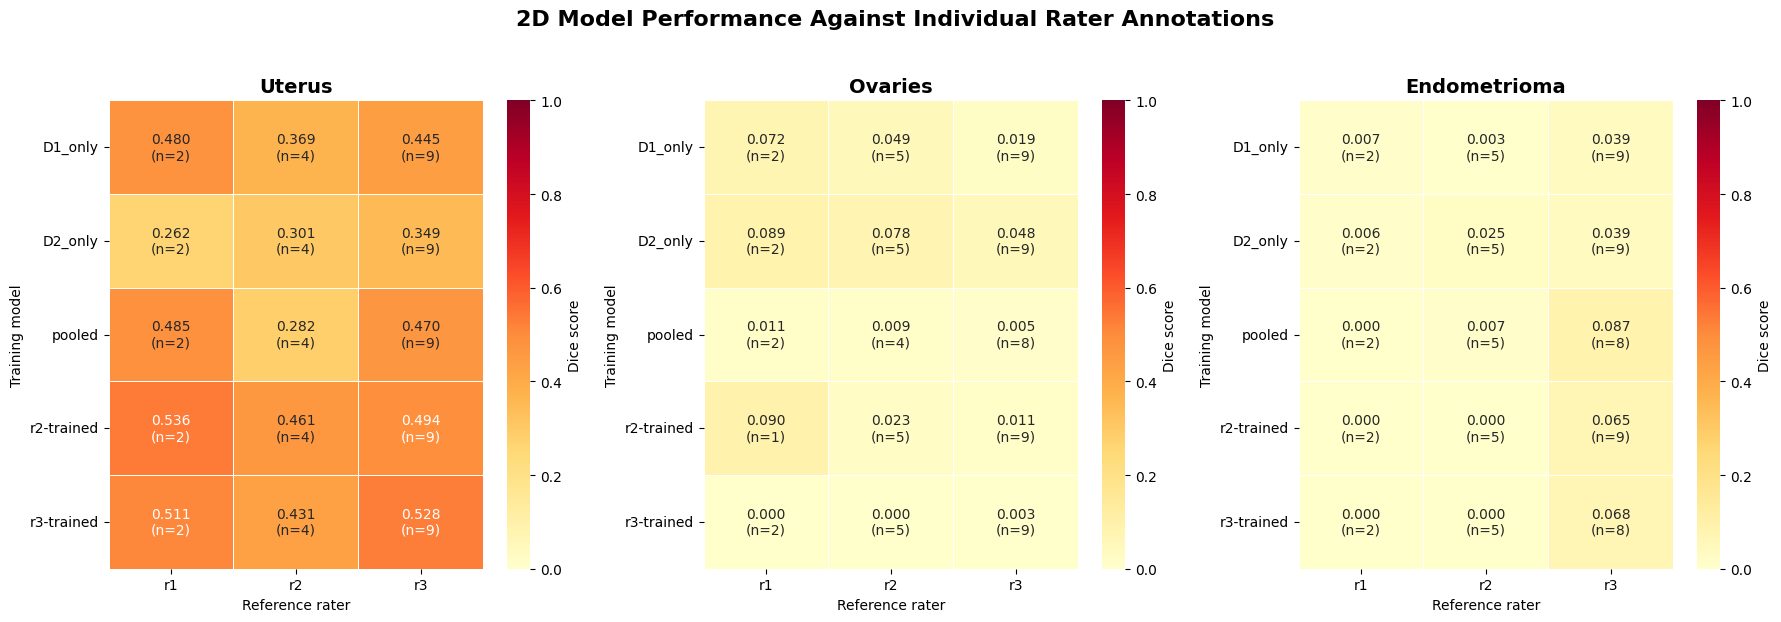

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Rows and columns
models = ["D1_only", "D2_only", "pooled", "r2-trained", "r3-trained"]
raters = ["r1", "r2", "r3"]

# Dice scores
data = {
    "Uterus": [
        [0.480, 0.369, 0.445],
        [0.262, 0.301, 0.349],
        [0.485, 0.282, 0.470],
        [0.536, 0.461, 0.494],
        [0.511, 0.431, 0.528]
    ],
    "Ovaries": [
        [0.072, 0.049, 0.019],
        [0.089, 0.078, 0.048],
        [0.011, 0.009, 0.005],
        [0.090, 0.023, 0.011],
        [0.000, 0.000, 0.003]
    ],
    "Endometrioma": [
        [0.007, 0.003, 0.039],
        [0.006, 0.025, 0.039],
        [0.000, 0.007, 0.087],
        [0.000, 0.000, 0.065],
        [0.000, 0.000, 0.068]
    ]
}

# Sample sizes
sample_sizes = {
    "Uterus": [
        [2, 4, 9],
        [2, 4, 9],
        [2, 4, 9],
        [2, 4, 9],
        [2, 4, 9]
    ],
    "Ovaries": [
        [2, 5, 9],
        [2, 5, 9],
        [2, 4, 8],
        [1, 5, 9],
        [2, 5, 9]
    ],
    "Endometrioma": [
        [2, 5, 9],
        [2, 5, 9],
        [2, 5, 8],
        [2, 5, 9],
        [2, 5, 8]
    ]
}

# Create one figure with three heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, organ in zip(axes, data.keys()):
    df = pd.DataFrame(data[organ], index=models, columns=raters)

    # Annotation: Dice score + sample size
    annotations = np.empty(df.shape, dtype=object)

    for i in range(df.shape[0]):
        for j in range(df.shape[1]):
            annotations[i, j] = (
                f"{df.iloc[i, j]:.3f}\n(n={sample_sizes[organ][i][j]})"
            )

    sns.heatmap(
        df,
        ax=ax,
        annot=annotations,
        fmt="",
        cmap="YlOrRd",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        linecolor="white",
        cbar=True,
        cbar_kws={"label": "Dice score"},
        annot_kws={"size": 10}
    )

    ax.set_title(organ, fontsize=14, fontweight="bold")
    ax.set_xlabel("Reference rater")
    ax.set_ylabel("Training model")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "2D Model Performance Against Individual Rater Annotations",
    fontsize=16,
    fontweight="bold",
    y=1.03
)

plt.tight_layout()
plt.savefig("rater_comparison_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

In [1]:
import sys, torch, numpy, pandas, nibabel, skimage, scipy, matplotlib, seaborn
print("Python", sys.version.split()[0])
for m in [torch, numpy, pandas, nibabel, skimage, scipy, matplotlib, seaborn]:
    print(m.__name__, m.__version__)

Python 3.13.16
torch 2.14.1+cu130
numpy 2.4.6
pandas 2.2.3
nibabel 5.4.2
skimage 0.25.2
scipy 1.16.3
matplotlib 3.10.0
seaborn 0.13.2
